In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from labels import prepare_labels, CLASSES
from scipy.ndimage import uniform_filter1d

DATA_DIR = Path("../data/raw/ptb-xl")
METADATA_PATH = DATA_DIR / "ptbxl_database.csv"

metadata = pd.read_csv(METADATA_PATH)
metadata = metadata.set_index("ecg_id", drop=False)

print("Количество записей в таблице:", len(metadata))

Количество записей в таблице: 21799


In [2]:
# Загружаем первую запись
first_ecg_id = metadata.index[0]
first_record_path = DATA_DIR / metadata.loc[first_ecg_id, "filename_lr"]
record = wfdb.rdrecord(str(first_record_path))

signal = record.p_signal

print("Размер сигнала:", signal.shape)
print("Частота дискретизации:", record.fs, "Гц")
print("Количество отведений:", len(record.sig_name))
print("Названия отведений:", record.sig_name)
print("Единицы измерения:", record.units)
print("Тип данных:", signal.dtype)
print("Продолжительность записи:", signal.shape[0]/record.fs, "секунд")

Размер сигнала: (1000, 12)
Частота дискретизации: 100 Гц
Количество отведений: 12
Названия отведений: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Единицы измерения: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Тип данных: float64
Продолжительность записи: 10.0 секунд


## Немного об экг
отведения экг: https://avatars.mds.yandex.net/i?id=78b64a462f20d36735907bbfceb4fa6f_sr-4900921-images-thumbs&n=13"

Стандартные отведения от конечностей:
- I отведение - левая рука и правая рука. 
- II отведение - левая нога и правая рука. 
- III отведение - левая нога и левая рука.

Усиленные однополюсные отведения от конечностей:
- aVR - усиленное отведение от правой руки. 
- aVL - усиленное отведение от левой руки. 
- aVF - усиленное отведение от левой ноги.

Грудные отведения: V1, V2, V3, V4, V5, V6

## Проверка структуры всех ЭКГ-записей

In [3]:
structure_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    structure_results.append({
        "ecg_id": ecg_id,
        "n_samples": signal.shape[0],
        "n_leads": signal.shape[1],
        "fs": rec.fs,
        "duration_sec": signal.shape[0]/rec.fs,
        "leads": tuple(rec.sig_name),
        "units": tuple(rec.units)})

structure_df = pd.DataFrame(structure_results)

print("Количество записей с одинаковой структурой:",
      ((structure_df["n_samples"] == 1000) & (structure_df["n_leads"] == 12) 
       & (structure_df["fs"] == 100) & (structure_df["duration_sec"] == 10)).sum())

print("Количество записей с другими названиями отведений:",
      (structure_df["leads"] != tuple(record.sig_name)).sum())

print("Количество записей с другими единицами измерения:",
      (structure_df["units"] != tuple(record.units)).sum())

Количество записей с одинаковой структурой: 21799
Количество записей с другими названиями отведений: 0
Количество записей с другими единицами измерения: 0


### Структура экг-сигналов

Каждая запись содержит 1000 временных отсчётов и 12 отведений. Во всех случаях частота дискретизации - 100 Гц, продолжительность записи - 10 секунд. Названия отведений и единицы измерения совпадают во всех записях. Все сигналы в mV (милливольты).

-> Структура входных экг-сигналов однородна. Это упрощает подготовку данных к обучению модели: сигналы можно объединять в единый массив фиксированного размера без дополнительного выравнивания длины, дополнения нулями или изменения частоты дискретизации.

## Визуализация ЭКГ-сигнала

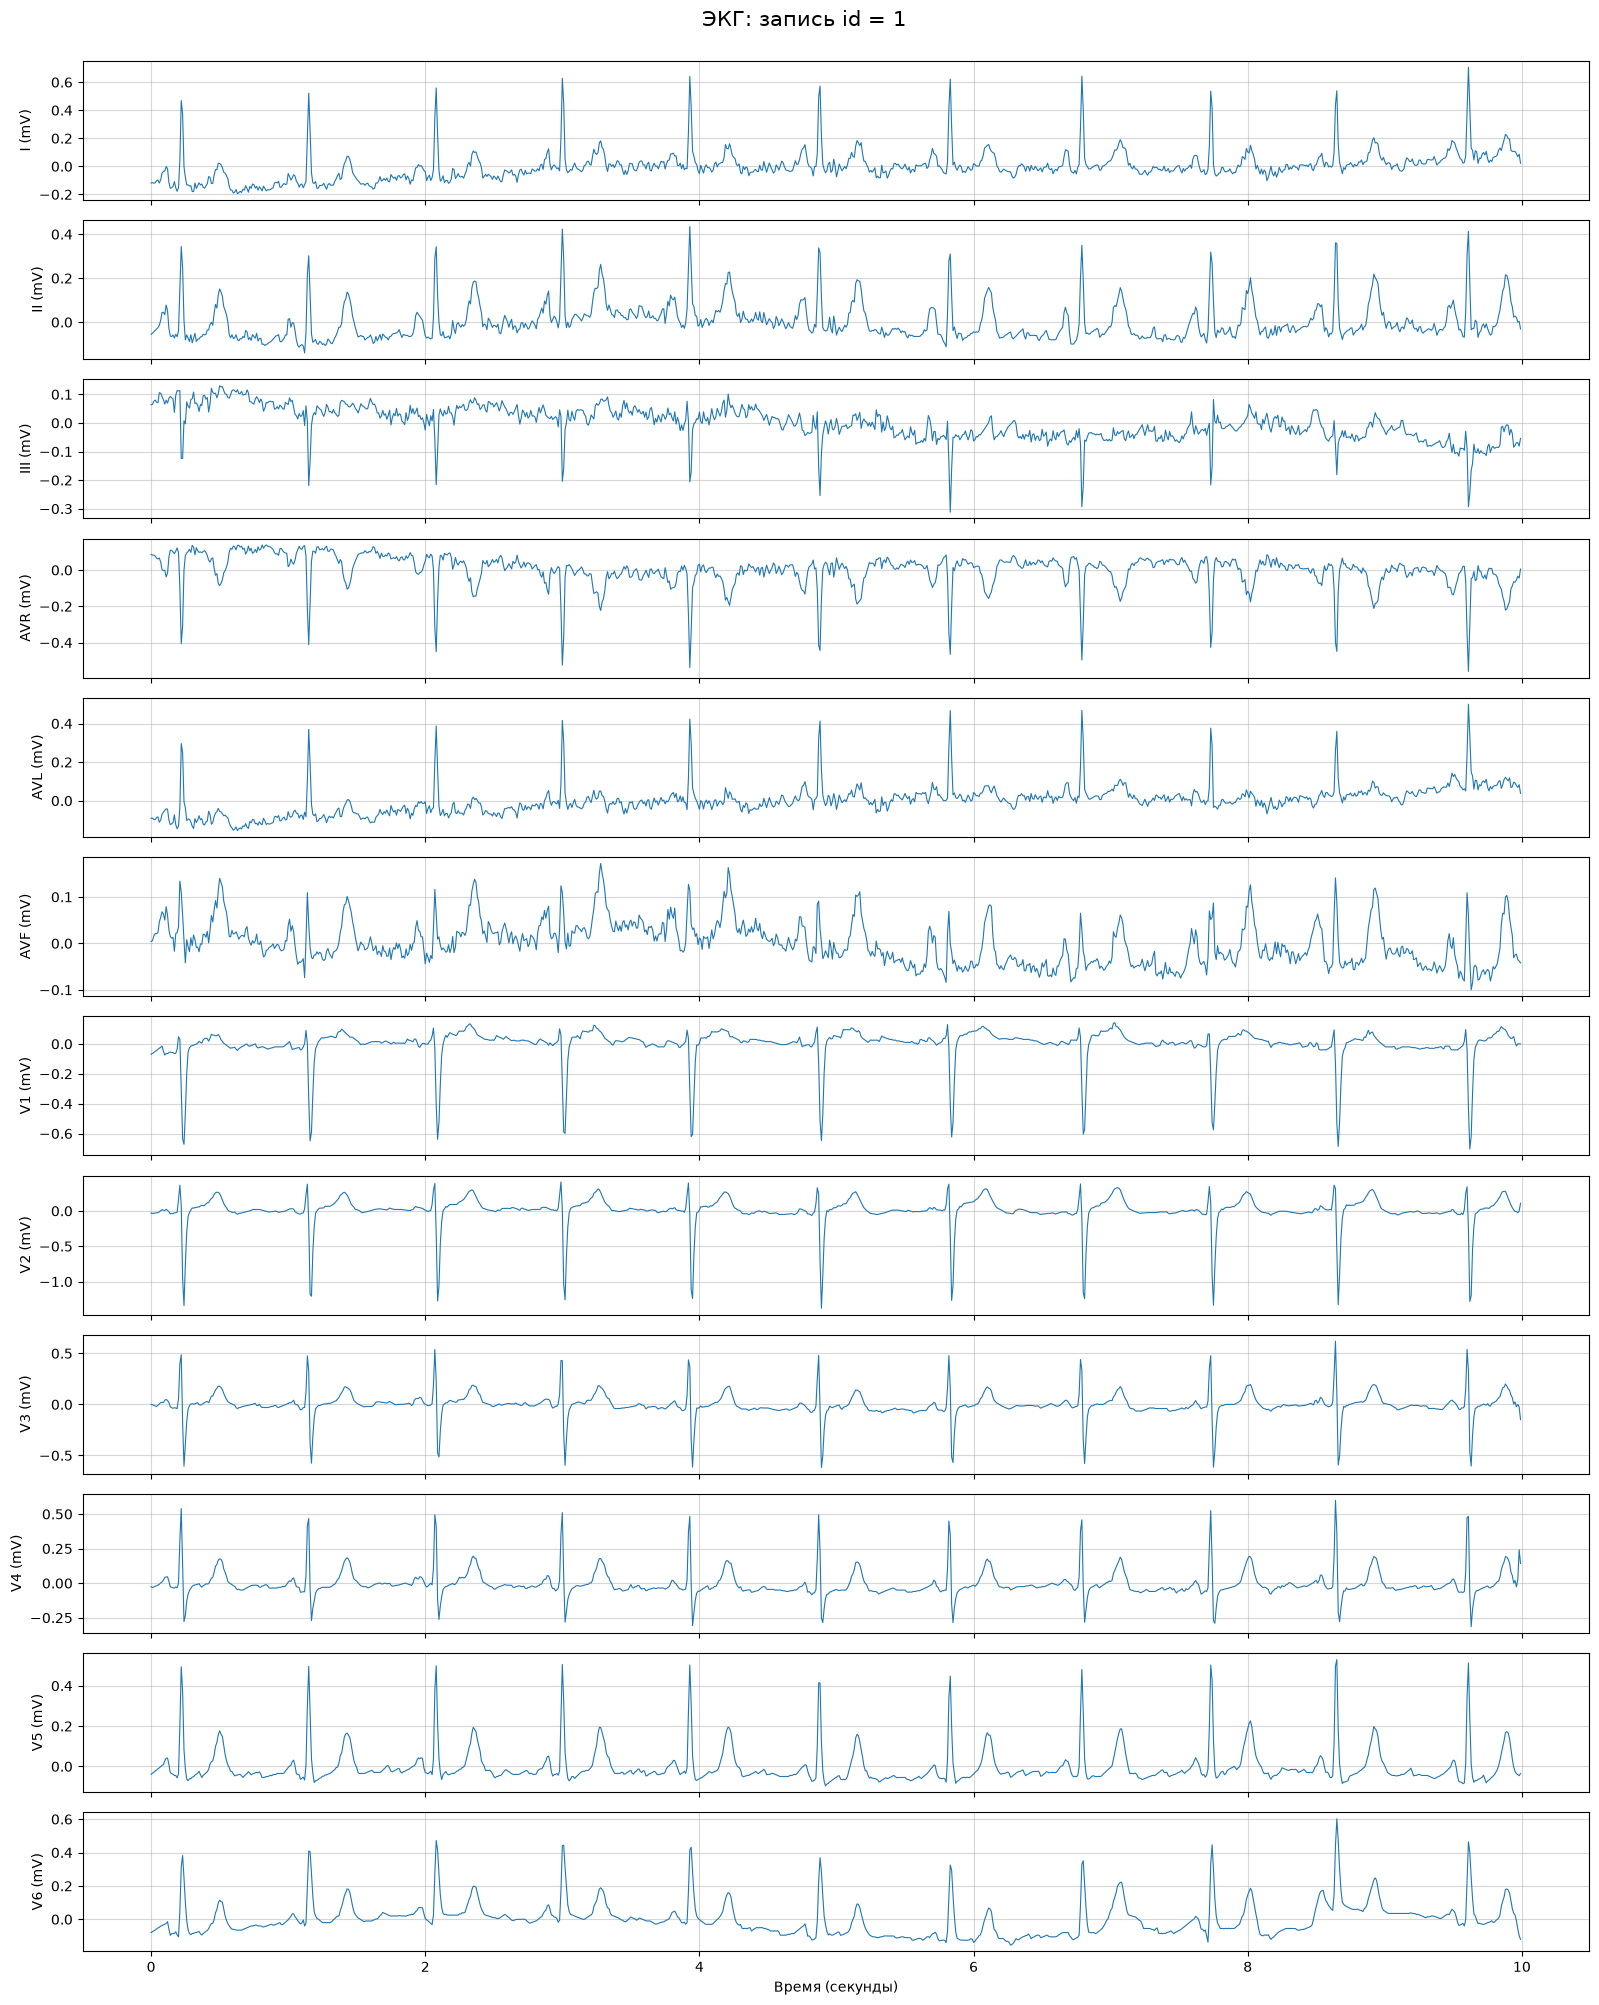

In [22]:
record = wfdb.rdrecord(str(first_record_path), physical=True)
signal = record.p_signal

time = np.arange(signal.shape[0])/record.fs
fig, axes = plt.subplots(12, 1, figsize=(16, 20), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(time, signal[:, i], linewidth=0.8)
    ax.set_ylabel(f"{record.sig_name[i]} (mV)")
    ax.grid(alpha=0.5)

axes[-1].set_xlabel("Время (секунды)")
fig.suptitle(f"ЭКГ: запись id = {first_ecg_id}", fontsize=15, y=1)

plt.tight_layout()
plt.show()

Сигналы разных отведений отличаются по форме и амплитуде. Встречаются положительные и отрицательные отклонения. Форма грудных и конечностных отведений заметно отличается.

На некоторых участках заметны медленные изменения сигнала и небольшие колебания. Это может быть связано с дрейфом и помехами/шумом.

Отведения имеют свои особенности, поэтому нужно сохранять все отведения и не считать их полностью взаимозаменяемыми.

## Разбиение на классы
(по файлу Ульяны)

In [5]:
labels_df = prepare_labels(METADATA_PATH, DATA_DIR / "scp_statements.csv")

display(labels_df.head())

,ecg_id,patient_id,strat_fold,NORM,MI,STTC,CD,HYP,n_labels,has_target_label
0,1,15709.0,3,1,0,0,0,0,1,True
1,2,13243.0,2,1,0,0,0,0,1,True
2,3,20372.0,5,1,0,0,0,0,1,True
3,4,17014.0,3,1,0,0,0,0,1,True
4,5,17448.0,4,1,0,0,0,0,1,True


## Сравнение ЭКГ-сигналов внутри каждого класса

In [6]:
records_by_class = {}

# Выбираем записи только с одним классом
for class_name in CLASSES:
    candidates = labels_df[(labels_df[class_name] == 1) & (labels_df["n_labels"] == 1)].sort_values("ecg_id")
    records_by_class[class_name] = candidates["ecg_id"].head(3).tolist() # по 3 записи для каждого класса

print("Выбранные записи:")
for class_name, ecg_ids in records_by_class.items():
    print(f"{class_name}: {ecg_ids}")

Выбранные записи:
NORM: [1, 2, 3]
MI: [8, 63, 131]
STTC: [22, 26, 28]
CD: [32, 41, 49]
HYP: [30, 96, 138]


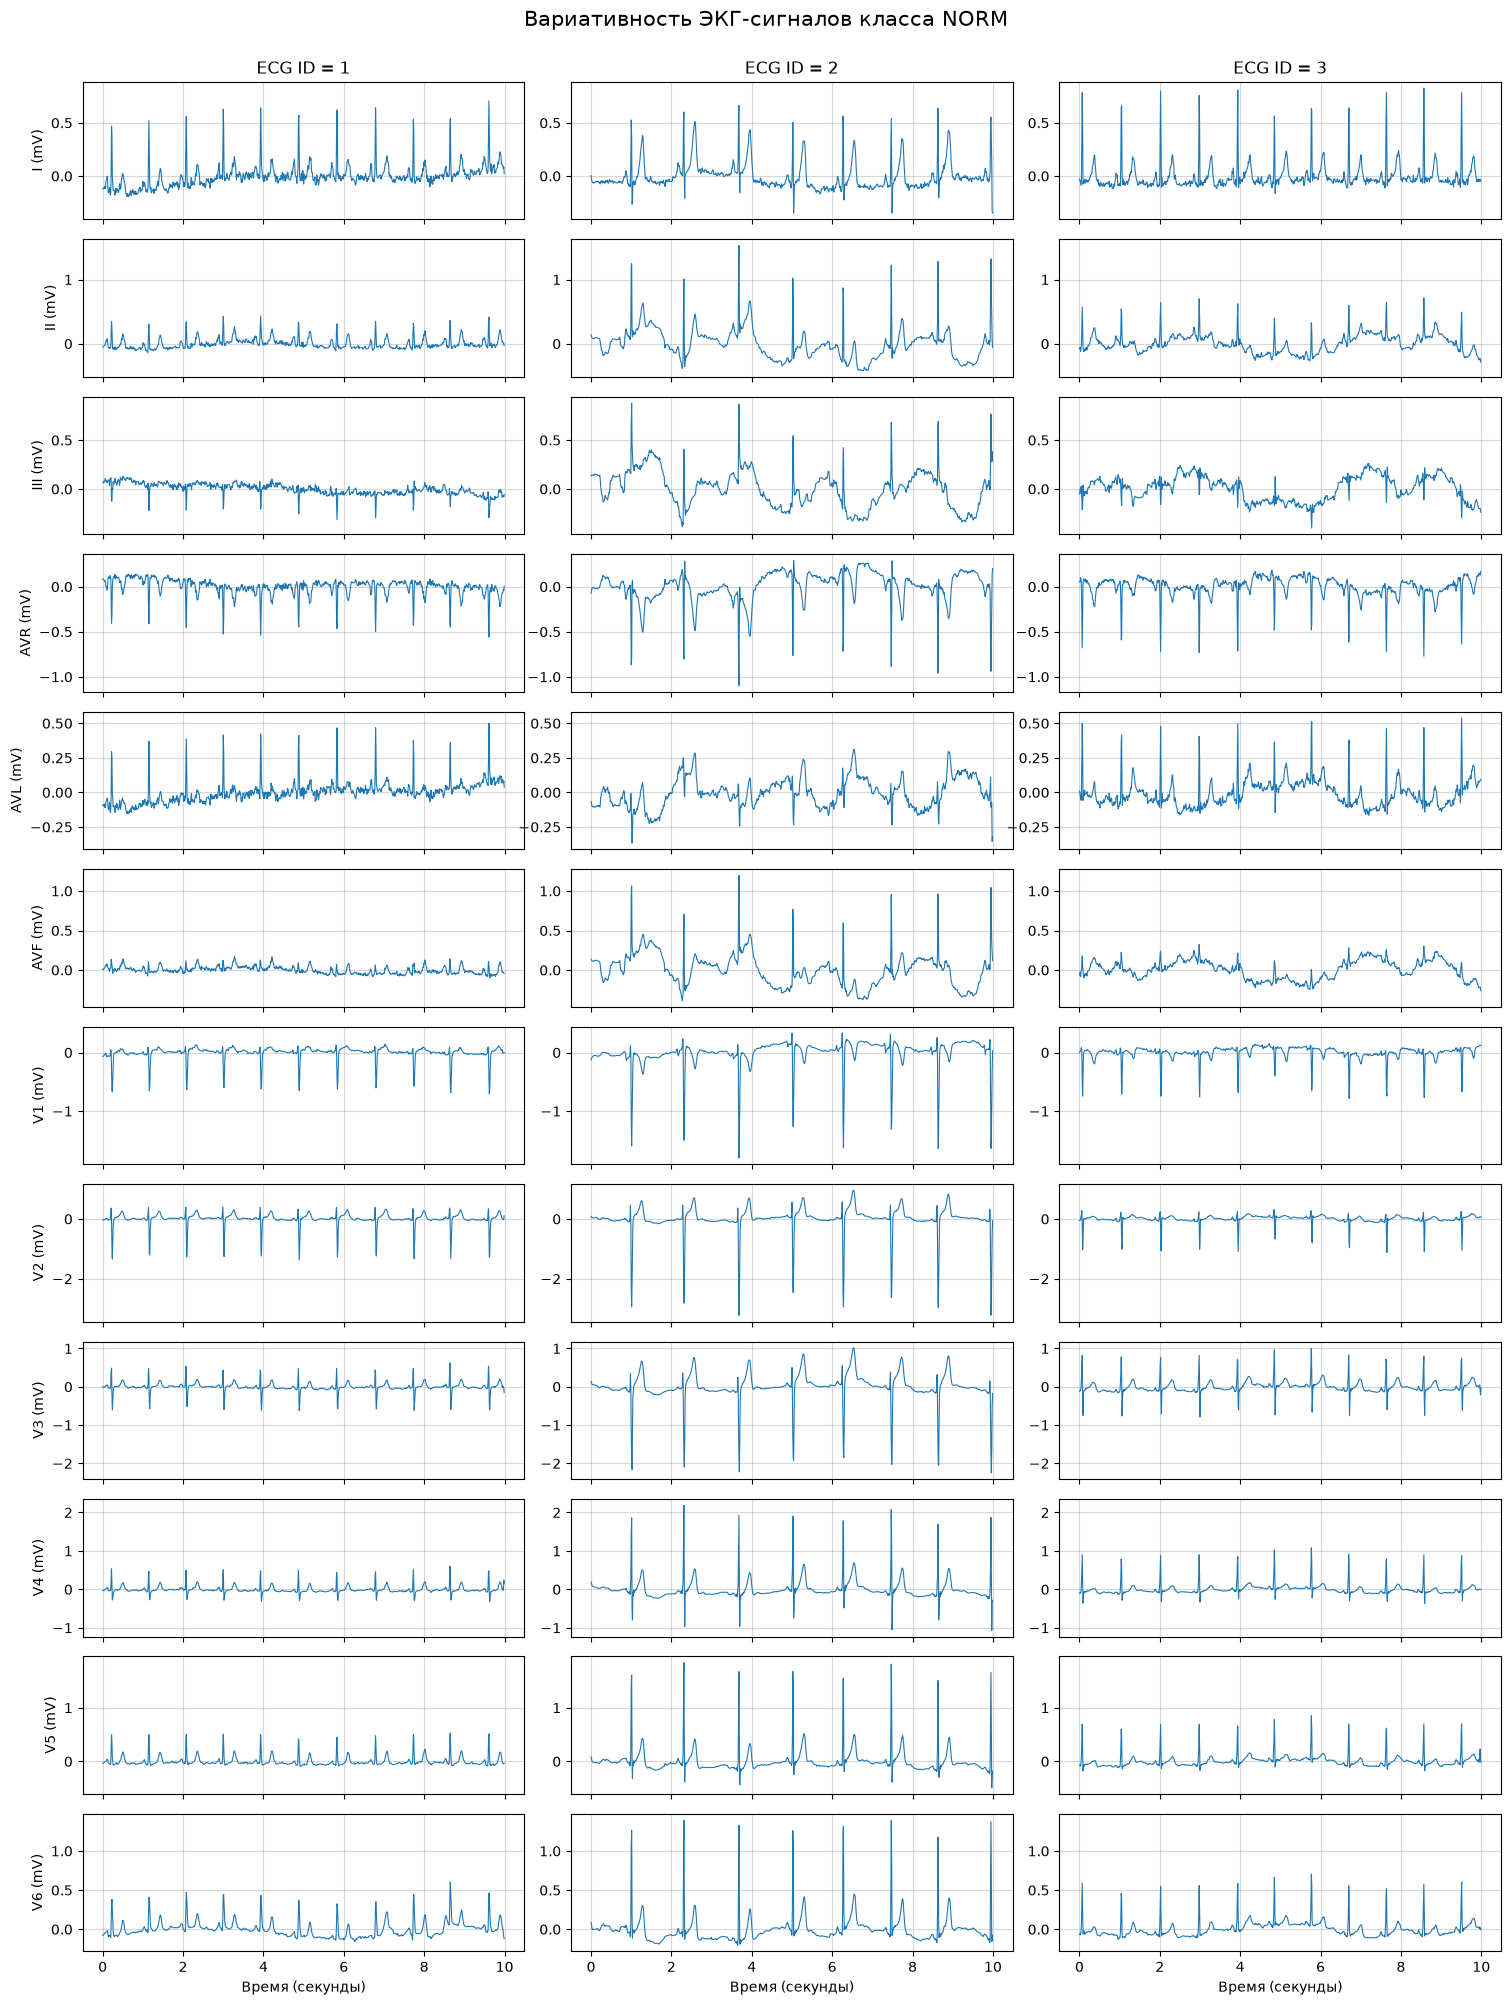

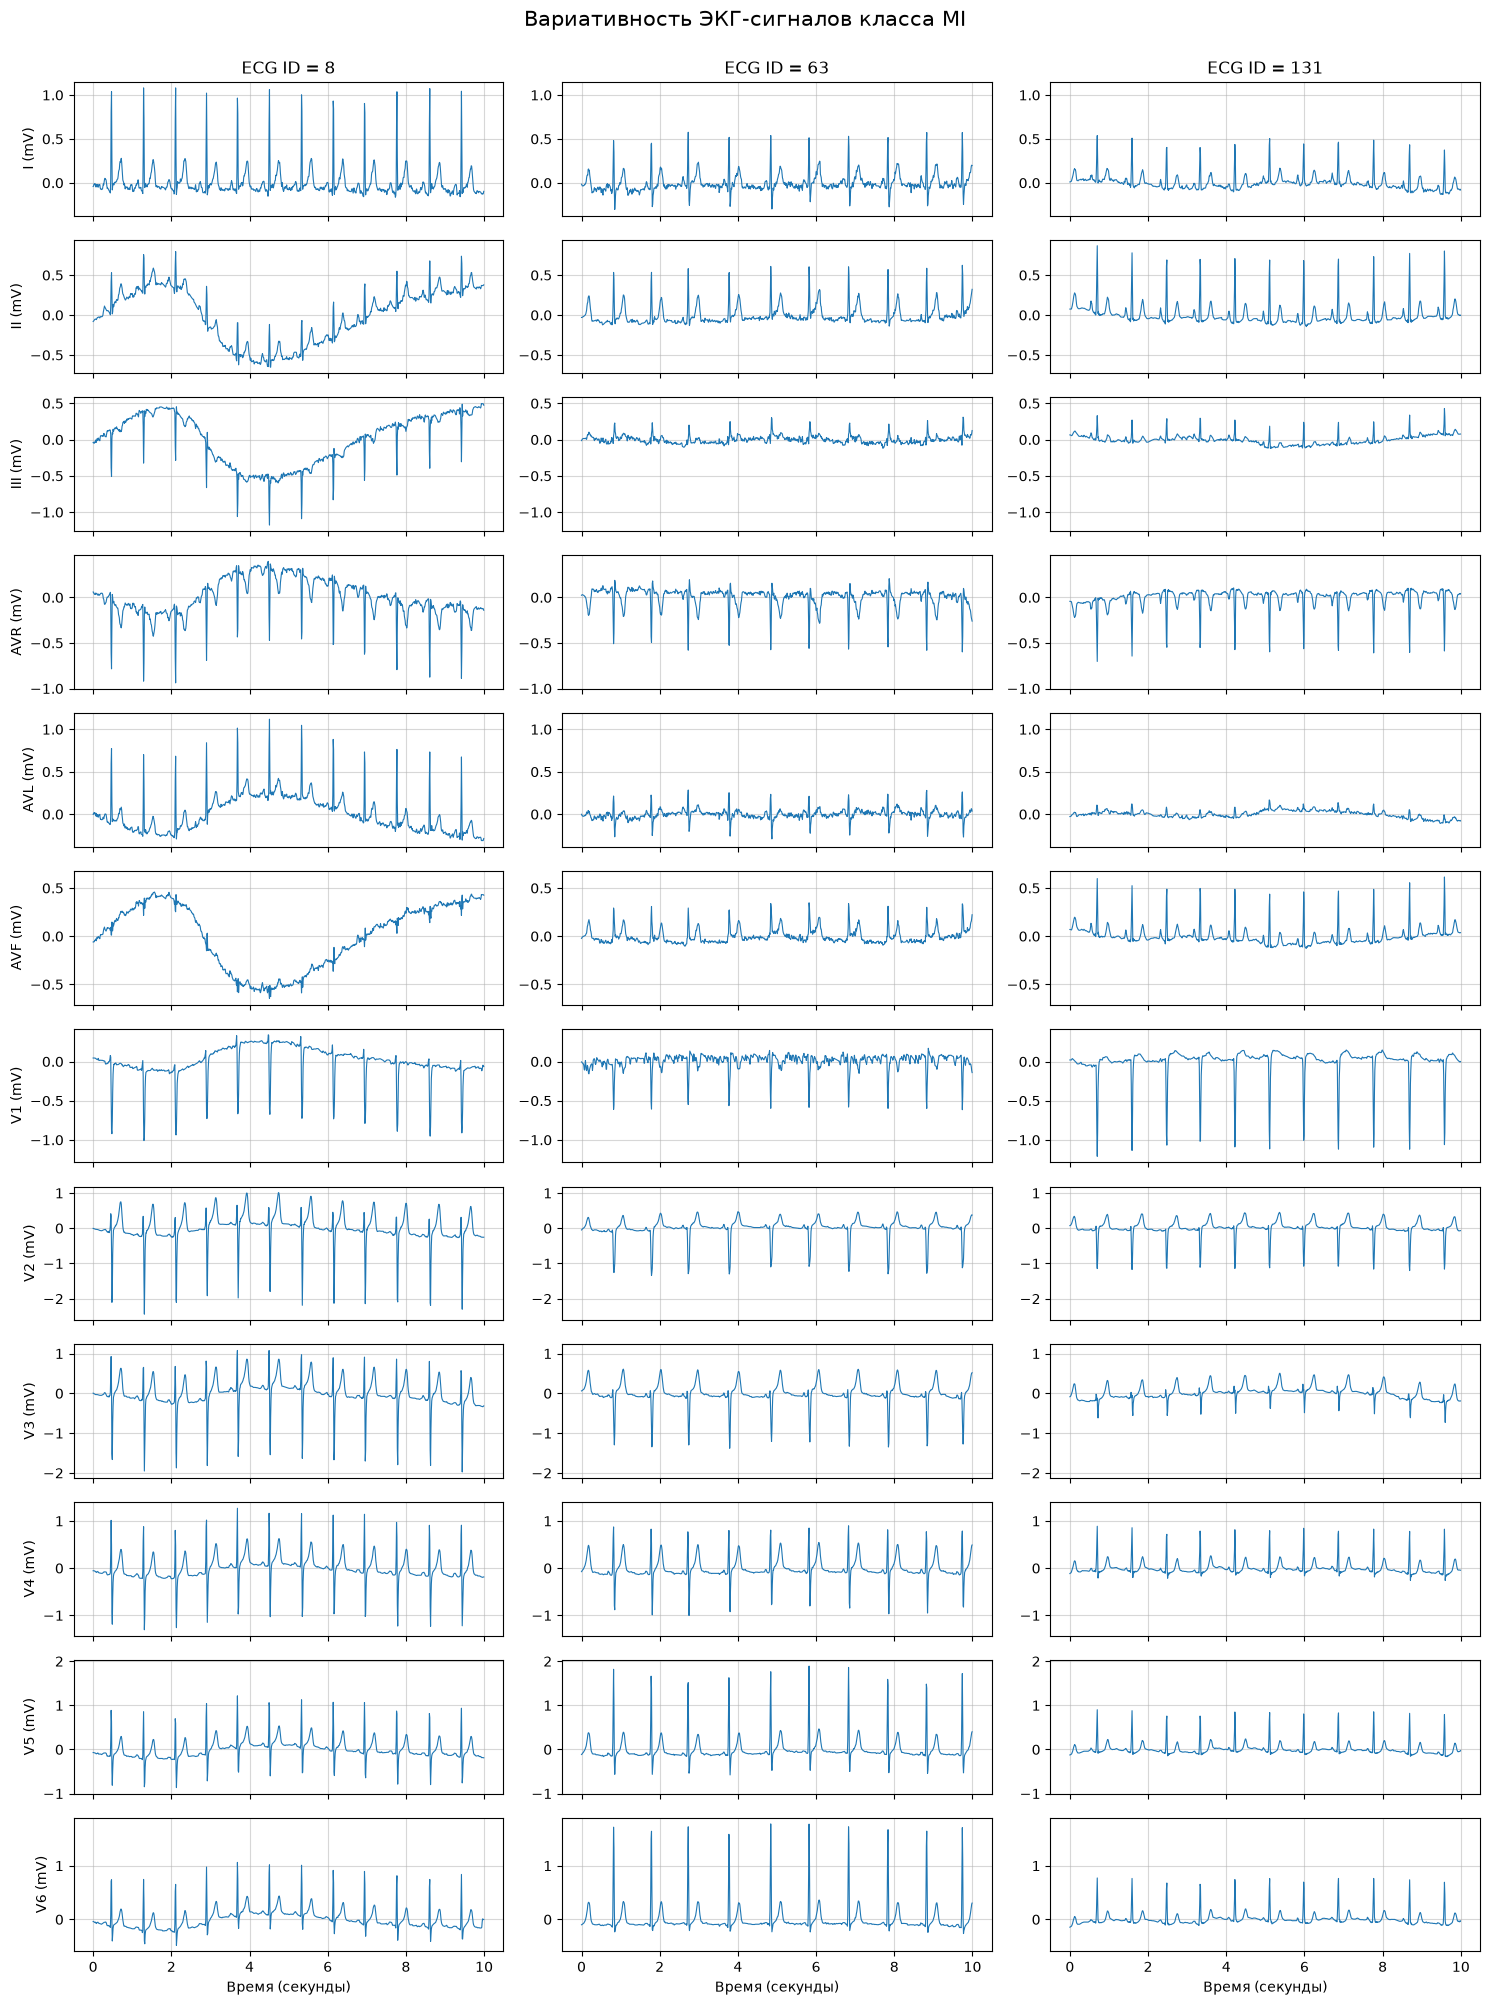

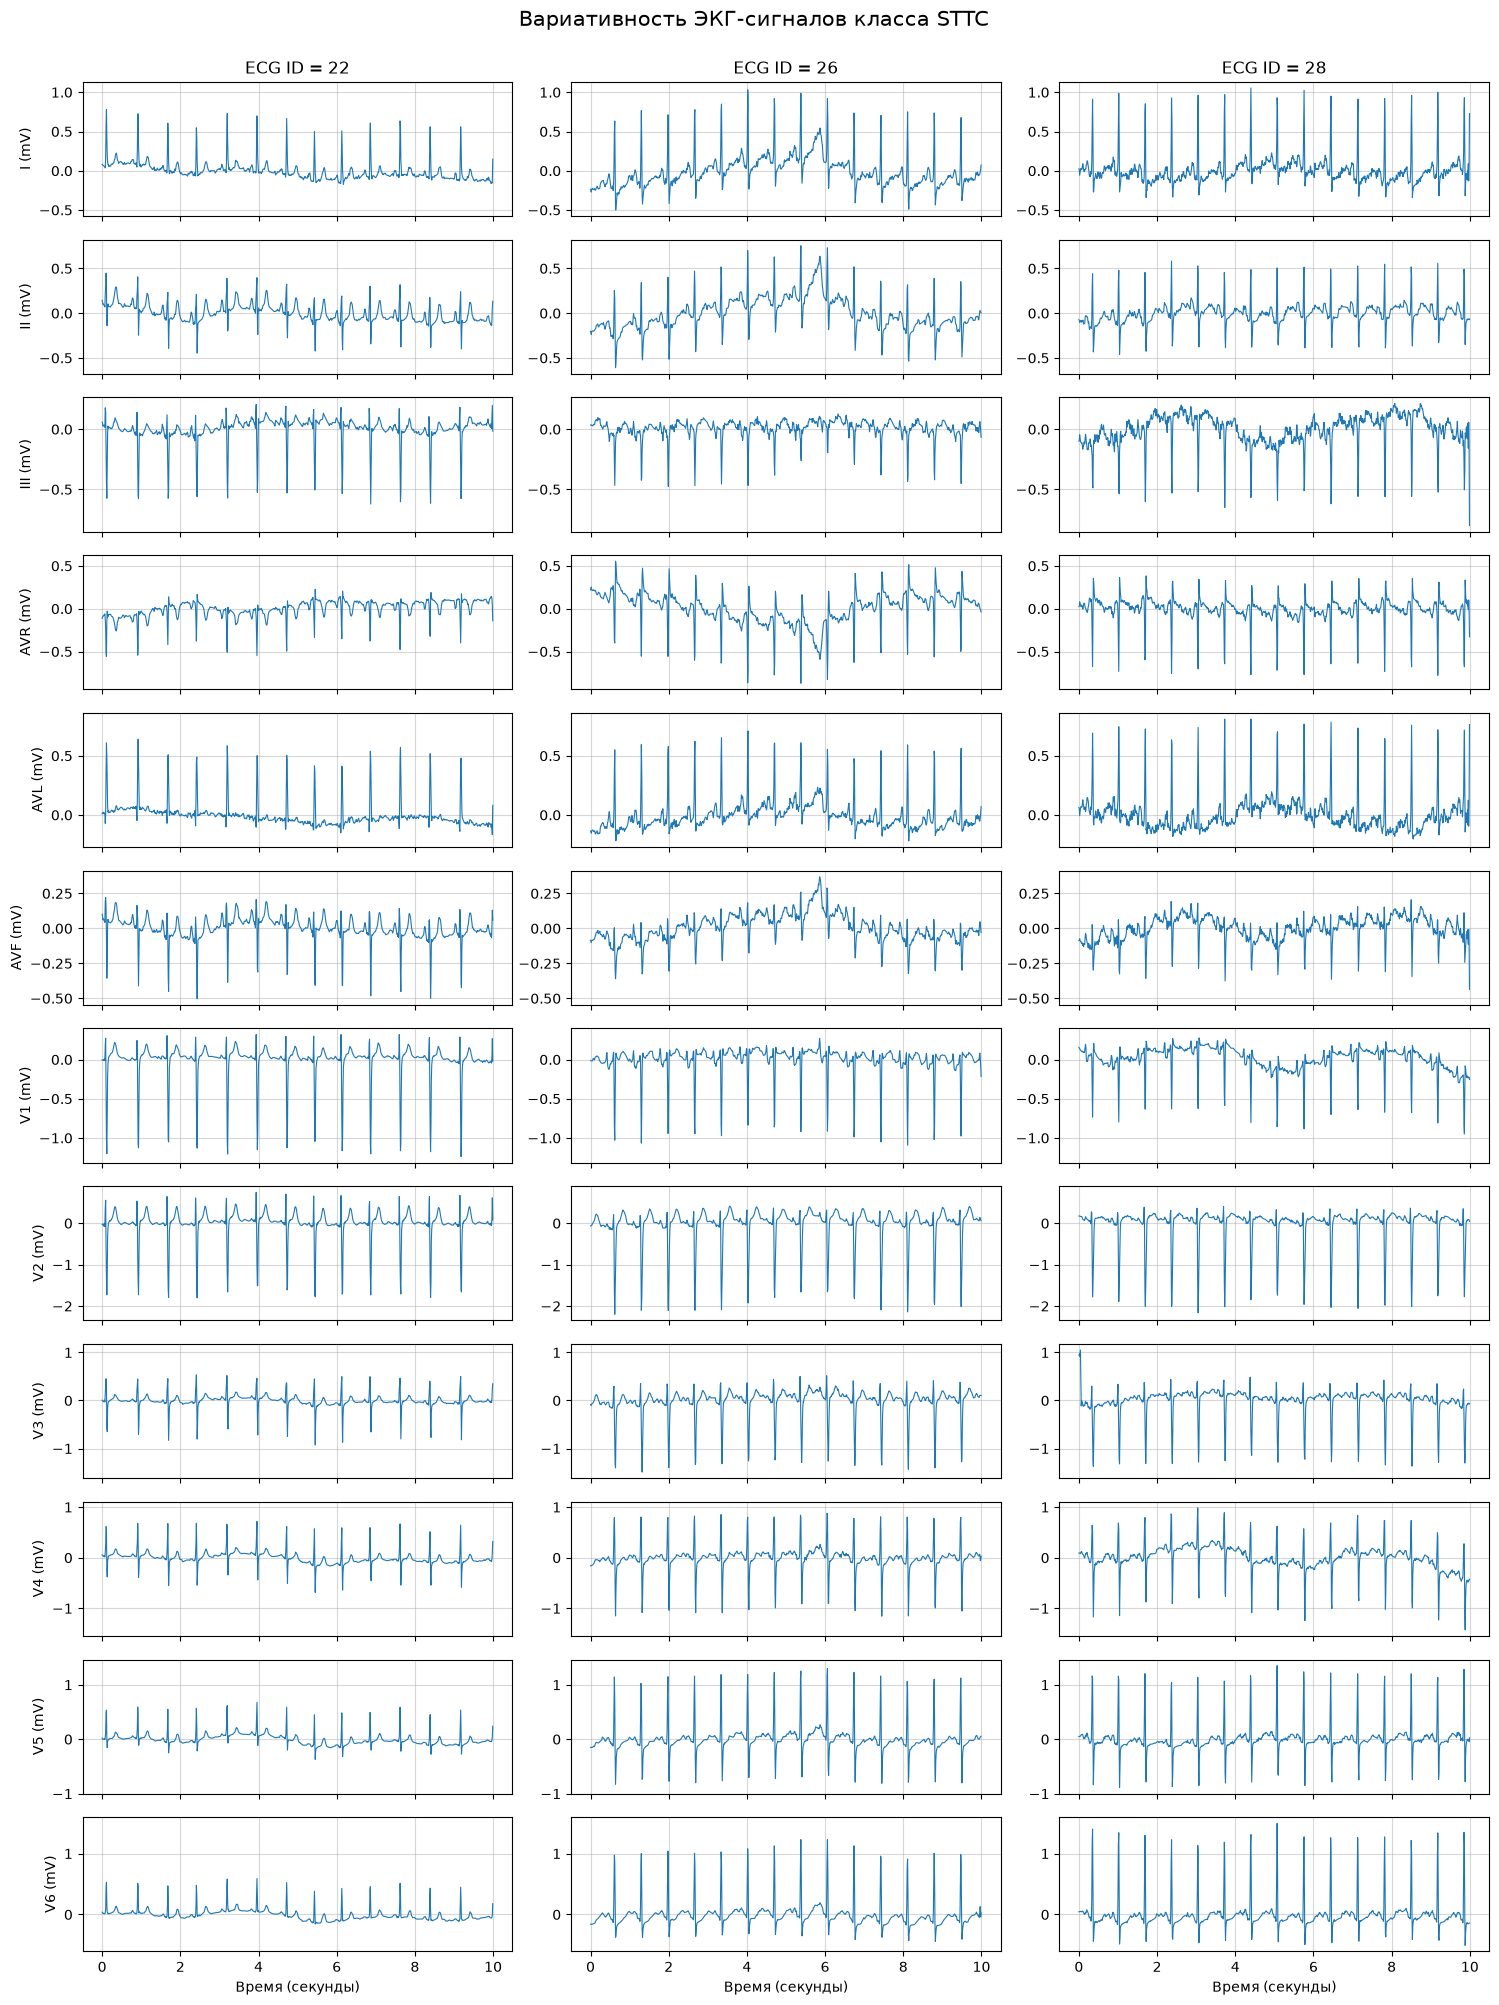

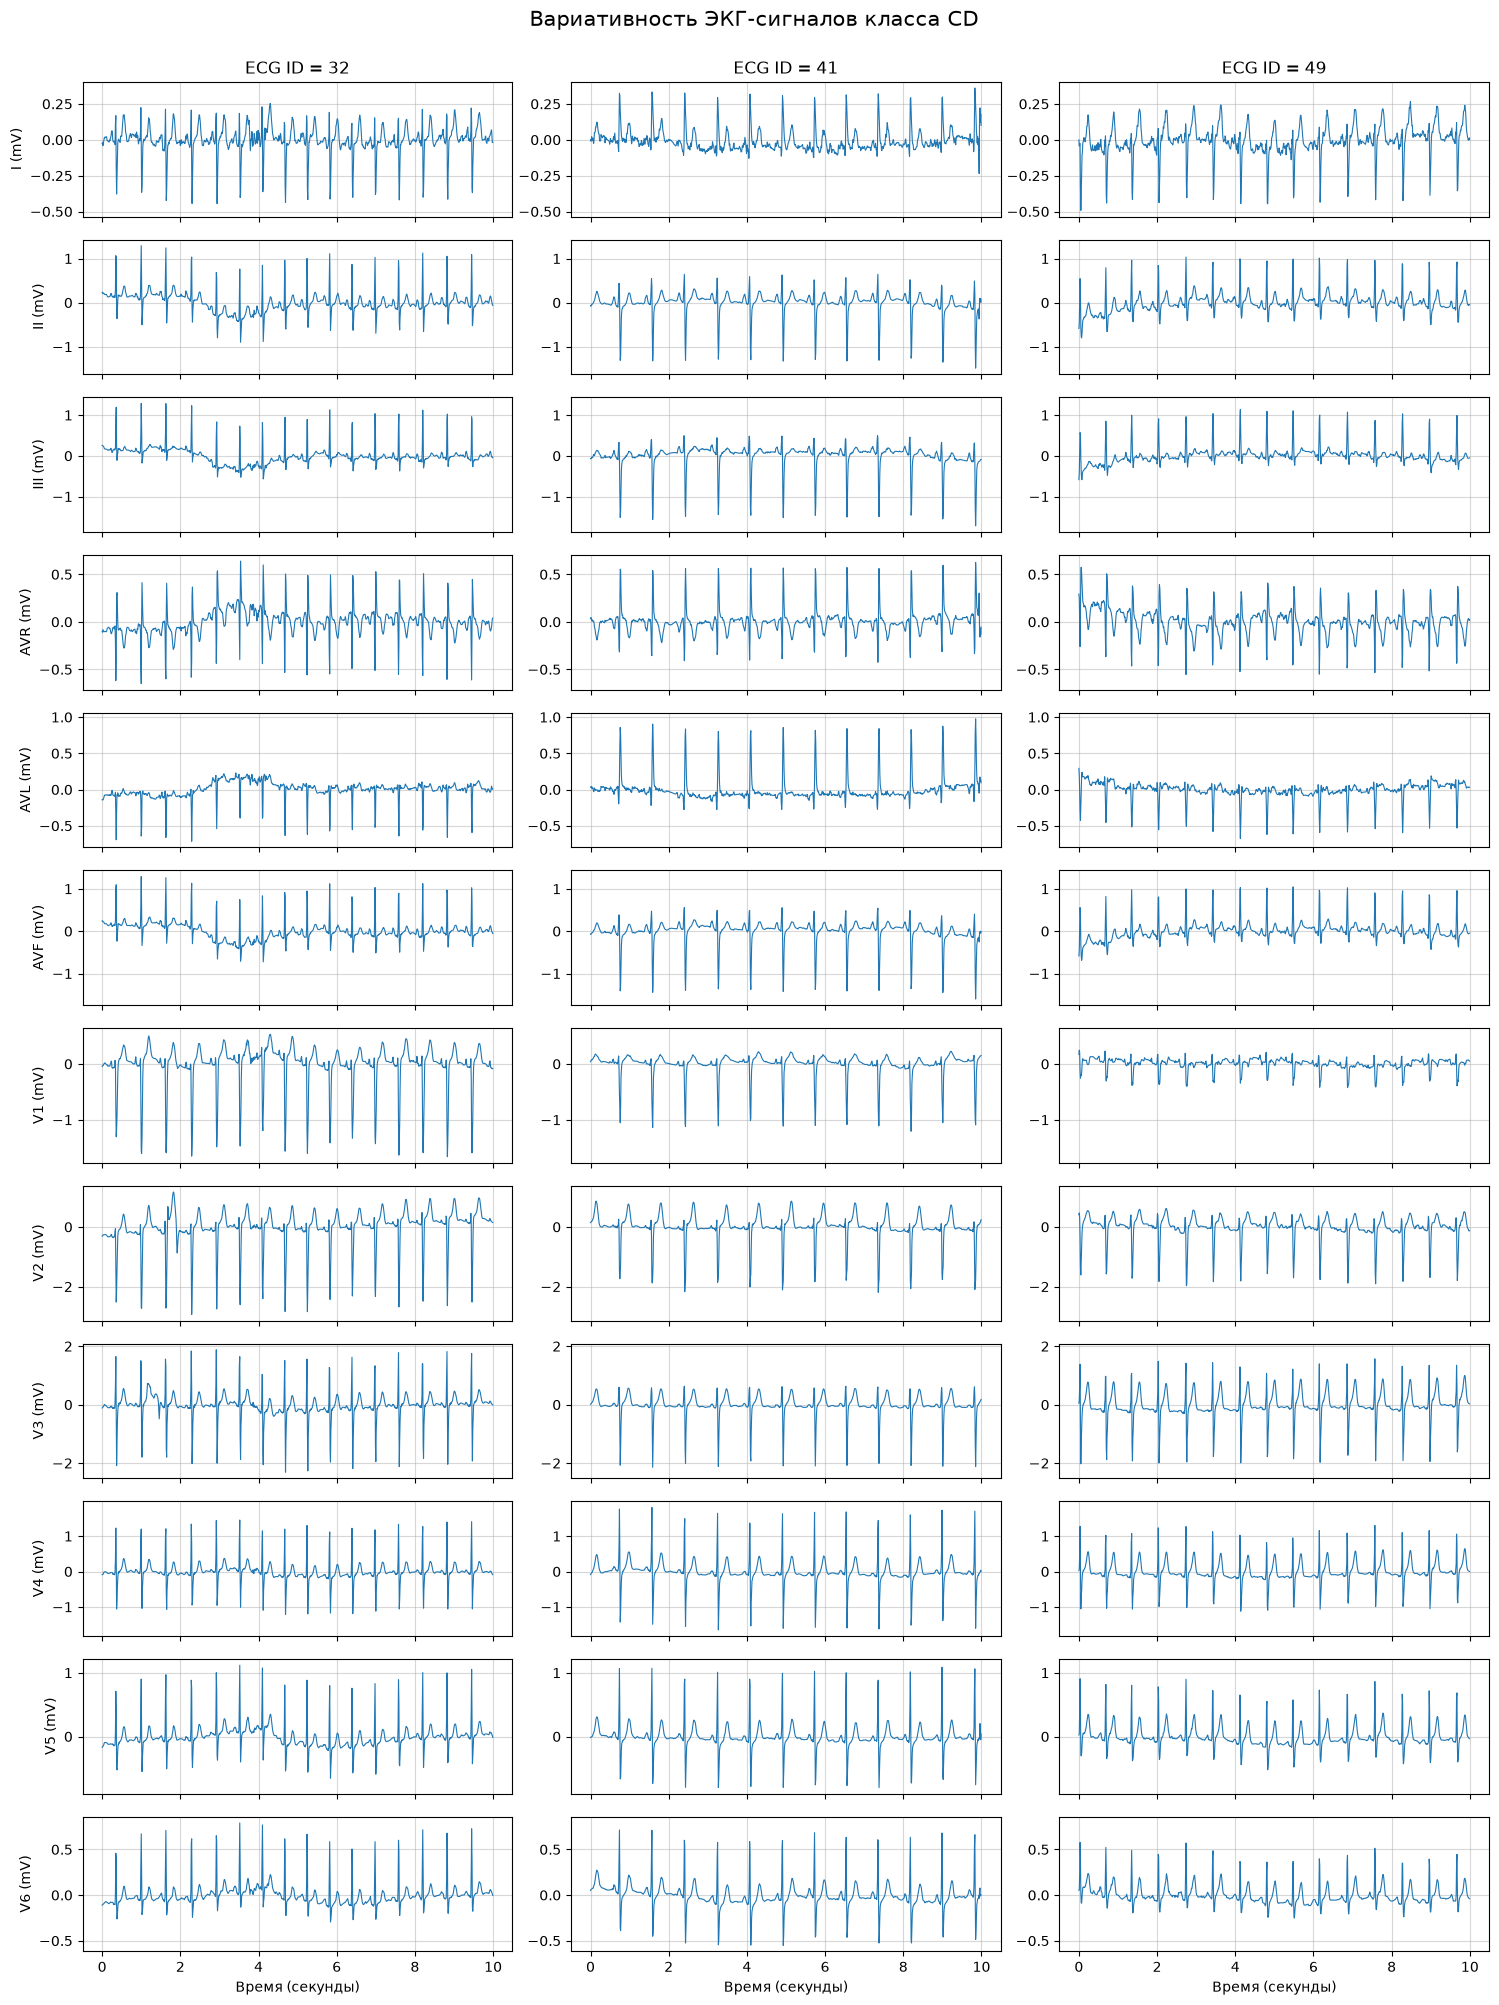

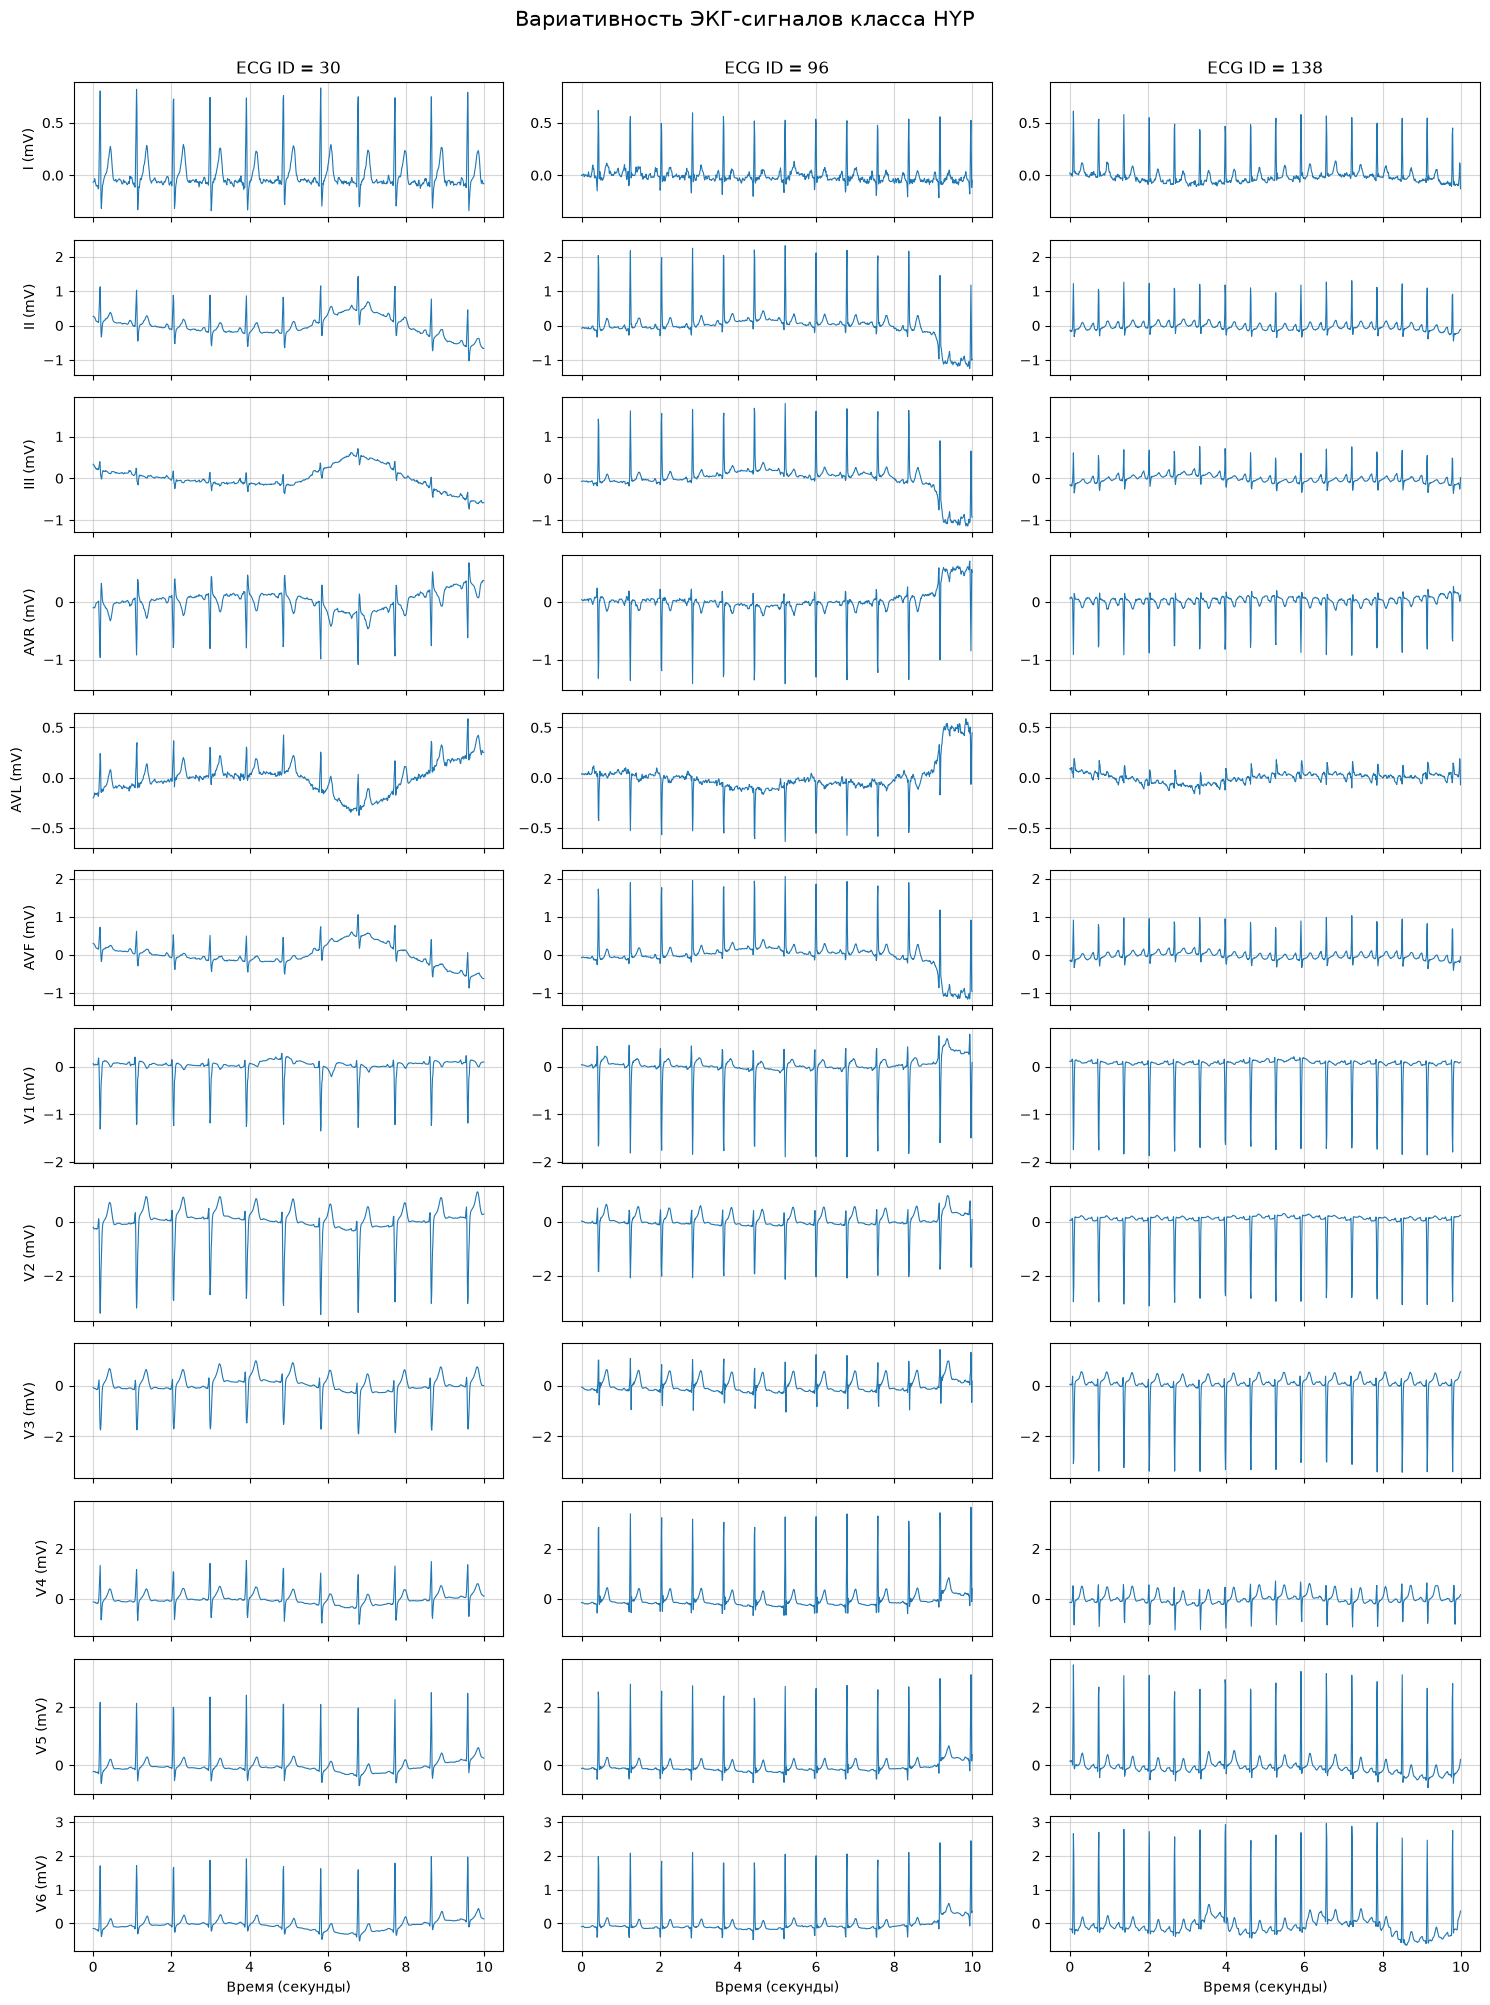

In [8]:
# отдельный график для каждого класса
for class_name, ecg_ids in records_by_class.items():

    fig, axes = plt.subplots(12, 3, figsize=(15, 20), sharex=True)

    signals = []

    for ecg_id in ecg_ids:
        row = metadata.loc[ecg_id]
        record_path = DATA_DIR / row["filename_lr"]
        rec = wfdb.rdrecord(str(record_path))
        signals.append(rec.p_signal)

    time =  np.arange(signals[0].shape[0])/rec.fs
    lead_names = rec.sig_name

    for lead_idx in range(12):
        all_values = np.concatenate([signal[:, lead_idx] for signal in signals])
        y_min = all_values.min()
        y_max = all_values.max()
        margin = (y_max - y_min) * 0.05
        for col, ecg_id in enumerate(ecg_ids):
            ax = axes[lead_idx, col]

            ax.plot(time, signals[col][:, lead_idx], linewidth=0.8)

            ax.set_ylim(y_min - margin, y_max + margin)
            ax.grid(alpha=0.5)

            if col == 0:
                ax.set_ylabel(f"{lead_names[lead_idx]} (mV)")

            if lead_idx == 0:
                ax.set_title(f"ECG ID = {ecg_id}")

            if lead_idx == 11:
                ax.set_xlabel("Время (секунды)")

    fig.suptitle(f"Вариативность ЭКГ-сигналов класса {class_name}", fontsize=15, y=1)

    plt.tight_layout()
    plt.show()

Для оценки разнообразия сигналов визуализированы первые три записи **с одной меткой** для каждого из классов: NORM, MI, STTC, CD и HYP.

Наблюдения:
- Даже внутри одного класса есть видимые различия в форме и амплитуде сигналов -> одна запись не может полностью характеризовать особенности всего класса -> важно учитывать внутриклассовую вариативность и не строить выводы по одному или нескольким представителям класса.

- При подготовке входных данных может потребоваться единый способ масштабирования/нормализации. Но значимые различия между отведениями при этом должны остаться.

## Проверка целостности значений

In [9]:
quality_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    quality_results.append({
        "ecg_id": ecg_id,
        "nan_count": np.isnan(ecg_signal).sum(),
        "inf_count": np.isinf(ecg_signal).sum()})

quality_df = pd.DataFrame(quality_results)

print("Всего записей:", len(quality_df))
print("Записей с NaN:", (quality_df["nan_count"] > 0).sum())
print("Записей с Inf:", (quality_df["inf_count"] > 0).sum())

Всего записей: 21799
Записей с NaN: 0
Записей с Inf: 0


Во всех записях отсутствуют пропуски и бесконечные значения

## Поиск плоских участков

In [10]:
def longest_constant_part(values):
    """Максимальная длина последовательности одинаковых значений"""
    changes = np.concatenate([[True], values[1:] != values[:-1]])
    starts = np.flatnonzero(changes)
    lengths = np.diff(np.concatenate([starts, [len(values)]]))

    max_idx = np.argmax(lengths)
    return lengths[max_idx], values[starts[max_idx]]


constant_parts = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    for lead_idx, lead in enumerate(rec.sig_name):
        part_length, _ = longest_constant_part(ecg_signal[:, lead_idx])

        constant_parts.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "max_constant_samples": part_length,
            "max_constant_seconds": part_length/rec.fs})

constant_parts_df = pd.DataFrame(constant_parts)

# подозрительные участки - нет изменений 0,5 секунды (50 samples) и дольше
suspicious_parts = constant_parts_df[constant_parts_df["max_constant_samples"] >= 50].copy()

print("Проверено отведений:", len(constant_parts_df))
print("Отведений с постоянным участком от 0,5 секунды:", len(suspicious_parts))
print("Записей с такими участками:", suspicious_parts["ecg_id"].nunique())

print("10 самых длинных постоянных участков:")
display(constant_parts_df.sort_values("max_constant_samples", ascending=False).head(10))

Проверено отведений: 261588
Отведений с постоянным участком от 0,5 секунды: 7
Записей с такими участками: 4
10 самых длинных постоянных участков:


,ecg_id,lead,max_constant_samples,max_constant_seconds
152290,12722,V5,1000,10.00
240083,20045,V6,927,9.27
152291,12722,V6,828,8.28
231131,19299,V6,714,7.14
152289,12722,V4,369,3.69
231128,19299,V3,139,1.39
146638,12251,V5,85,0.85
133269,11132,V4,44,0.44
199242,16641,V1,43,0.43
146778,12263,V1,42,0.42


In [11]:
def get_longest_constant_part(values):
    """Координаты и длина самой длинной части"""
    changes = np.concatenate([[True], values[1:] != values[:-1]])
    starts = np.flatnonzero(changes)
    ends = np.concatenate([starts[1:], [len(values)]])
    lengths = ends - starts

    idx = np.argmax(lengths)

    return starts[idx], ends[idx], lengths[idx]


details = []

for _, item in suspicious_parts.iterrows():
    ecg_id = item["ecg_id"]
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = ecg_signal[:, lead_idx]

    start, end, length = get_longest_constant_part(values)

    details.append({
        "ecg_id": ecg_id,
        "lead": lead,
        "start_sec": start / rec.fs,
        "end_sec": end / rec.fs,
        "duration_sec": length / rec.fs,
        "constant_value_mV": values[start],
        "unique_values": len(np.unique(values))
    })

details_df = pd.DataFrame(details)

print("Подозрительные участки:")
display(details_df.sort_values("duration_sec", ascending=False).round(4))

Подозрительные участки:


,ecg_id,lead,start_sec,end_sec,duration_sec,constant_value_mV,unique_values
2,12722,V5,0.00,10.00,10.00,0.000,1
6,20045,V6,0.73,10.00,9.27,-20.022,65
3,12722,V6,1.72,10.00,8.28,0.000,26
5,19299,V6,2.86,10.00,7.14,0.000,204
1,12722,V4,6.31,10.00,3.69,0.000,354
4,19299,V3,8.61,10.00,1.39,-1.279,340
0,12251,V5,7.73,8.58,0.85,0.924,483


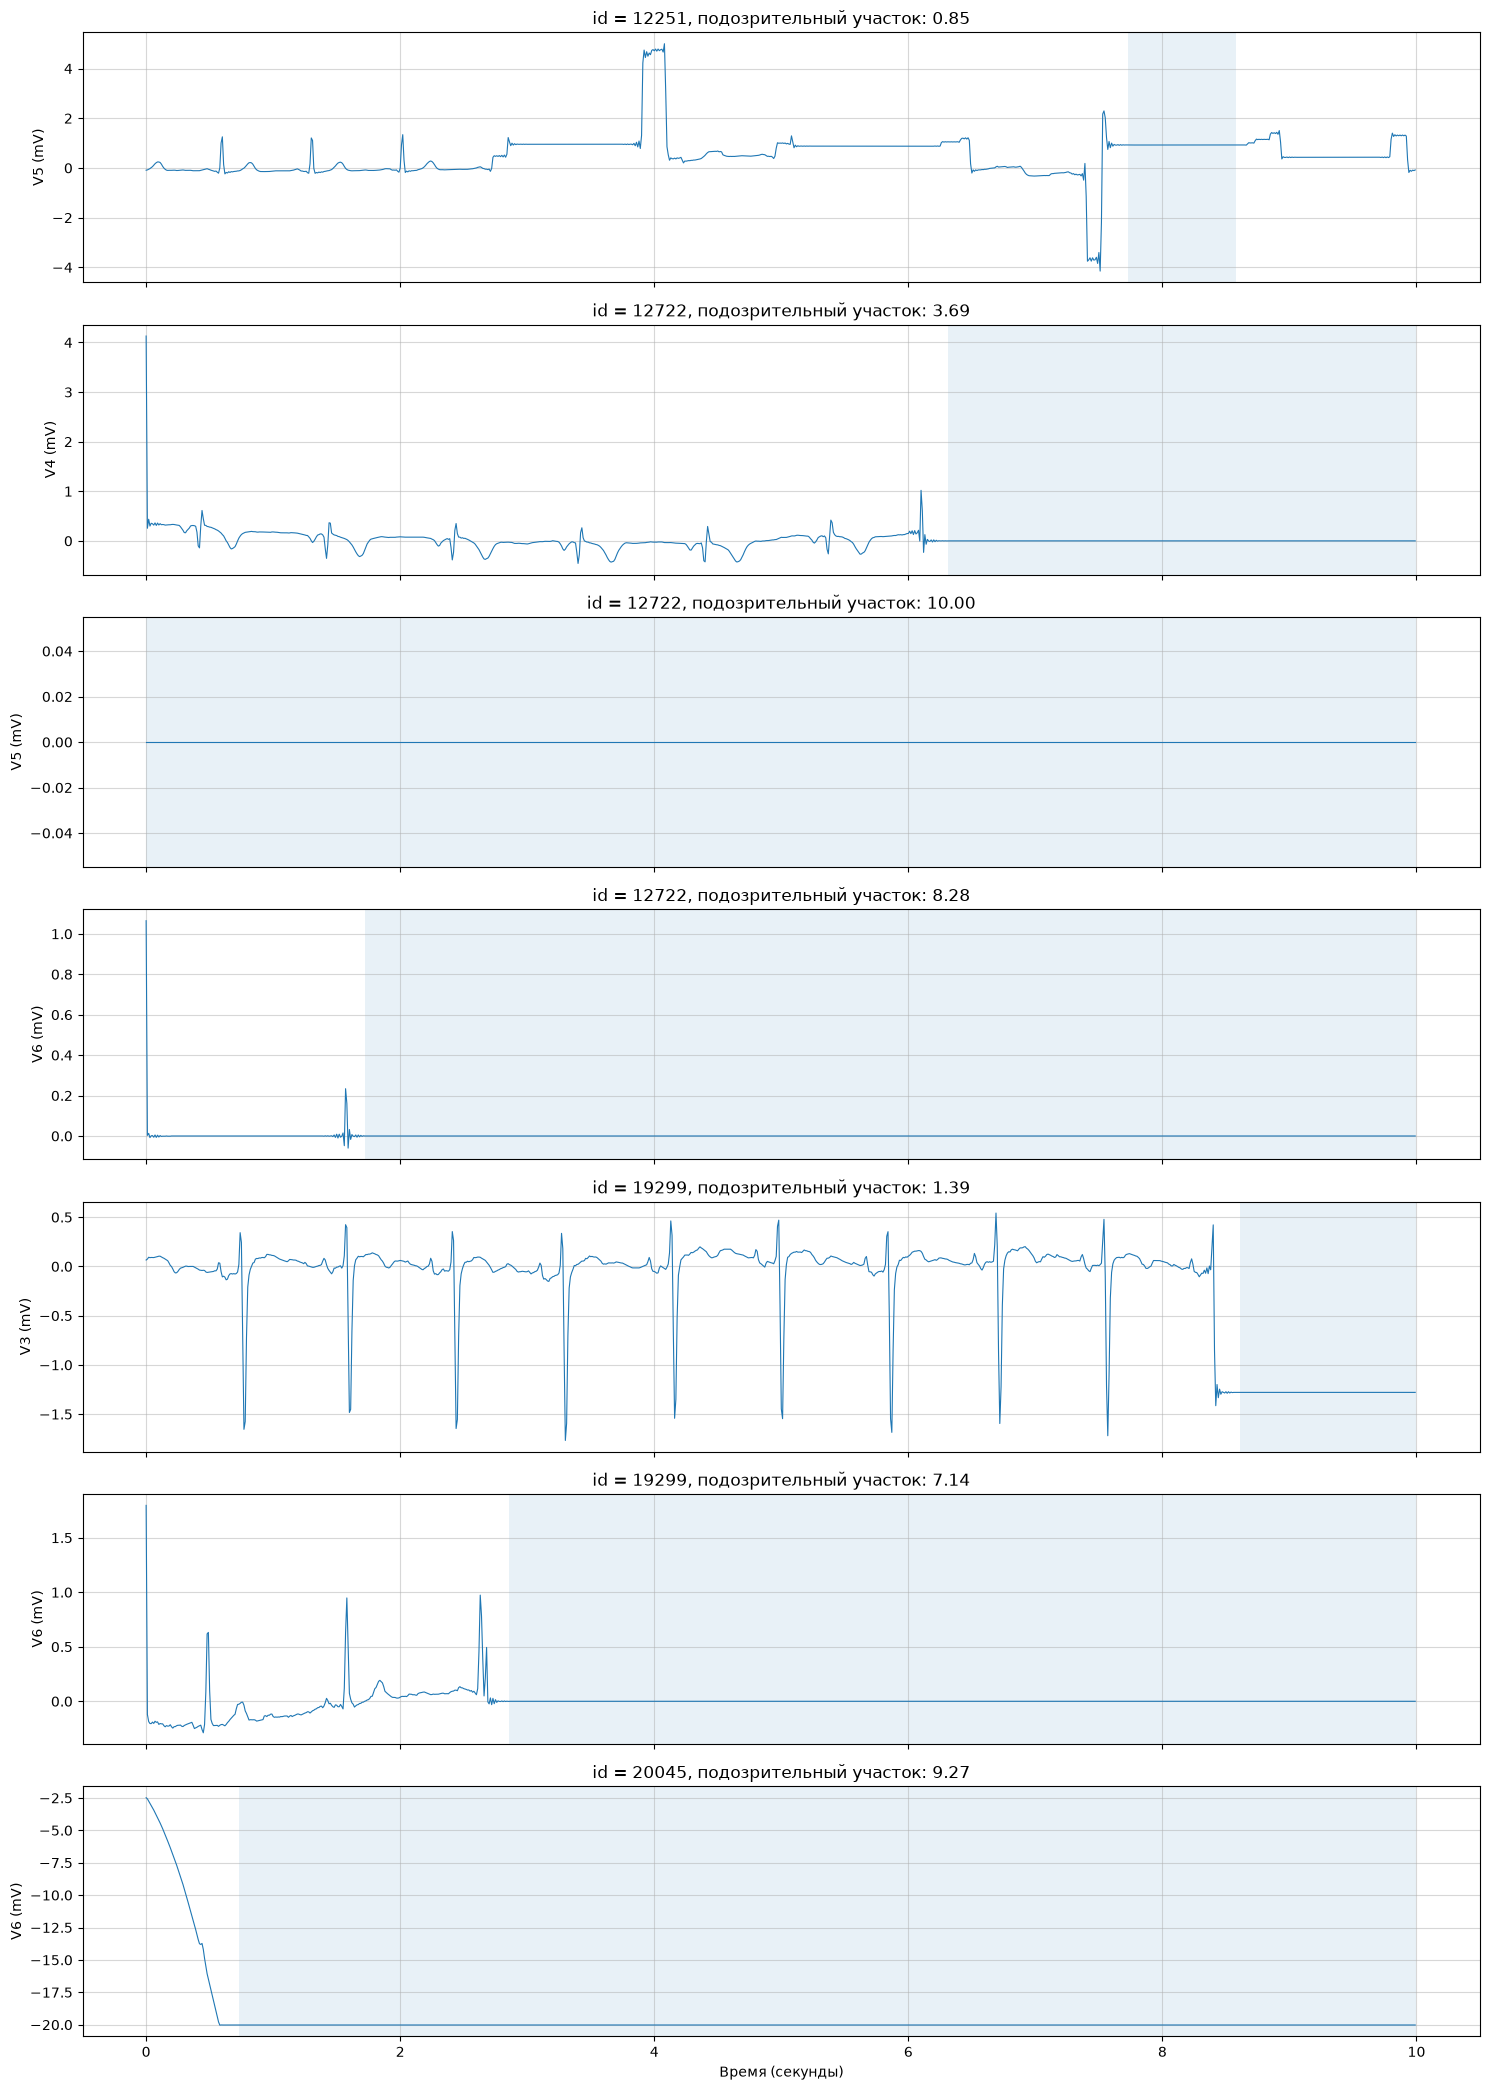

In [12]:
fig, axes = plt.subplots(len(details_df), 1, figsize=(15, 3 * len(details_df)), sharex=True)

for ax, (_, item) in zip(axes, details_df.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = ecg_signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    ax.plot(time, values, linewidth=0.8)

    # подозрительный участок
    ax.axvspan(item["start_sec"], item["end_sec"], alpha=0.1)

    ax.set_title(f"id = {ecg_id}, подозрительный участок: {item['duration_sec']:.2f}")

    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)

axes[-1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

**Вывод:**

В 4 записях найдено 7 отведений с непрерывными постоянными участками длительностью не менее 0,5 секунды.

Наиболее выраженные случаи в записях 12722, 20045 и 19299.
- В записи 12722 отведение V5 оставалось постоянным на протяжении всего времени. Отведения V4 и V6 этой записи тоже содержат длительный постоянный участок.
- В записи 20045 отведение V6 большую часть времени было неизменным и очень низким.

Это может быть потеря или искажение данных в отдельных каналах -> учесть при подготовке входных данных.

*Примечание:* проверяю только точное равенство соседних значений. Участки с малыми, но ненулевыми изменениями этот способ не проверяет.

## Проверка амплитуд

In [13]:
amplitude_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    for lead_idx, lead in enumerate(rec.sig_name):
        values = signal[:, lead_idx]

        amplitude_results.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "min_mV": np.min(values),
            "max_mV": np.max(values),
            "max_abs_mV": np.max(np.abs(values)),
            "range_mV": np.ptp(values)})

amplitude_df = pd.DataFrame(amplitude_results)
display(amplitude_df.head())

,ecg_id,lead,min_mV,max_mV,max_abs_mV,range_mV
0,1,I,-0.195,0.706,0.706,0.901
1,1,II,-0.140,0.435,0.435,0.575
2,1,III,-0.312,0.130,0.312,0.442
3,1,AVR,-0.559,0.138,0.559,0.697
4,1,AVL,-0.155,0.500,0.500,0.655


Для поиска экстремально больших значений найдем 95-й, 99-й и 99.9-й перцентили отдельно для каждого отведения.

In [14]:
lead_order = rec.sig_name

amplitude_percentiles = amplitude_df.groupby("lead")["max_abs_mV"].quantile([0.95, 0.99, 0.999]).unstack()
amplitude_percentiles.columns = ["p95_mV", "p99_mV", "p99_9_mV"]
amplitude_percentiles = amplitude_percentiles.reindex(lead_order)

display(amplitude_percentiles.round(2))

,p95_mV,p99_mV,p99_9_mV
lead,,,
I,1.46,1.91,2.81
II,1.55,2.11,3.08
III,1.65,2.42,3.41
AVR,1.23,1.61,2.62
AVL,1.35,1.86,2.77
AVF,1.44,2.09,2.93
V1,1.98,2.91,5.70
V2,2.89,4.16,6.75
V3,2.85,4.29,7.04


Видно, что каждое отведение имеет собственное распределение максимальной абсолютной амплитуды -> амплитудные диапазоны различаются между отведениями и каждый из них надо рассматривать отдельно.

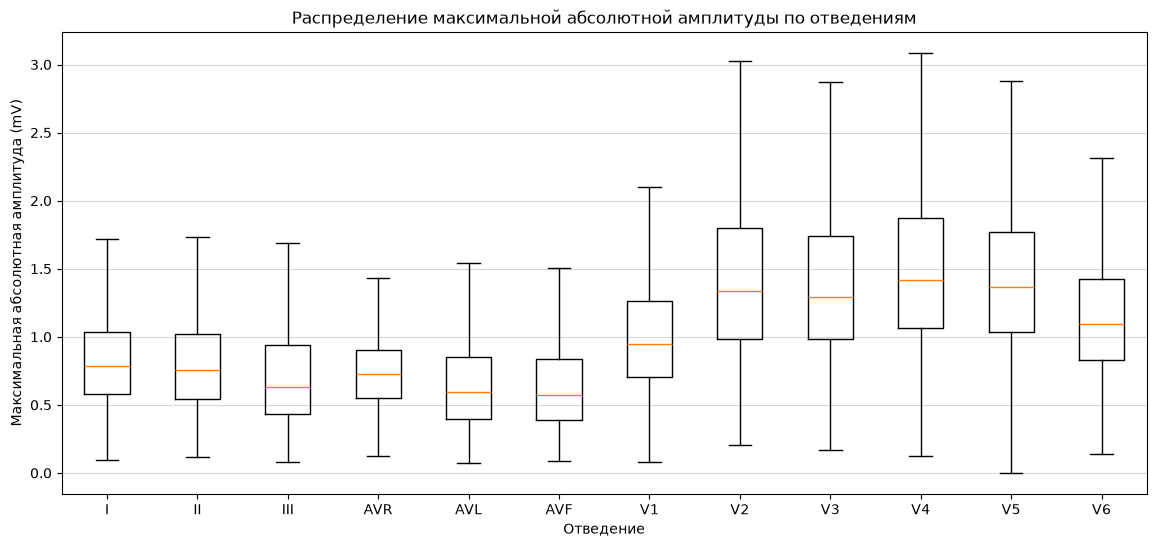

In [15]:
plt.figure(figsize=(14, 6))

amplitude_data = [amplitude_df.loc[amplitude_df["lead"] == lead, "max_abs_mV"] for lead in lead_order]

plt.boxplot(amplitude_data, tick_labels=lead_order, showfliers=False)
plt.title("Распределение максимальной абсолютной амплитуды по отведениям")
plt.xlabel("Отведение")
plt.ylabel("Максимальная абсолютная амплитуда (mV)")
plt.grid(axis="y", alpha=0.5)
plt.show()

У грудных отведений более высокое значение максимальной абсолютной амплитуды и бОльший разброс, чем у конечностных отведений.

-> необычные значения амплитуды будем сравнивать с перцентильным порогом отдельно для каждого отведения

In [16]:
amplitude_check = amplitude_df.join(amplitude_percentiles["p99_9_mV"], on="lead")
extreme_amplitudes = amplitude_check[amplitude_check["max_abs_mV"] > amplitude_check["p99_9_mV"]].copy()

print("Количество отведений с амплитудой выше p99.9:", len(extreme_amplitudes))
print("Количество ЭКГ-записей c такой амплитудой:", extreme_amplitudes["ecg_id"].nunique())

display(extreme_amplitudes.sort_values("max_abs_mV", ascending=False).head(10).round(3))

Количество отведений с амплитудой выше p99.9: 263
Количество ЭКГ-записей c такой амплитудой: 175


,ecg_id,lead,min_mV,max_mV,max_abs_mV,range_mV,p99_9_mV
240083,20045,V6,-20.032,-2.483,20.032,17.549,5.603
108294,9048,V1,-17.825,2.072,17.825,19.897,5.704
132118,11036,V5,2.278,17.212,17.212,14.934,6.295
129308,10802,V3,-16.320,4.539,16.320,20.859,7.045
234018,19540,V1,-16.126,2.846,16.126,18.972,5.704
148050,12369,V1,-15.395,3.966,15.395,19.361,5.704
176156,14716,V3,-14.916,2.306,14.916,17.222,7.045
260144,21717,V3,-14.725,2.910,14.725,17.635,7.045
171910,14362,V5,-13.055,3.319,13.055,16.374,6.295
133175,11124,V6,-5.091,12.966,12.966,18.057,5.603


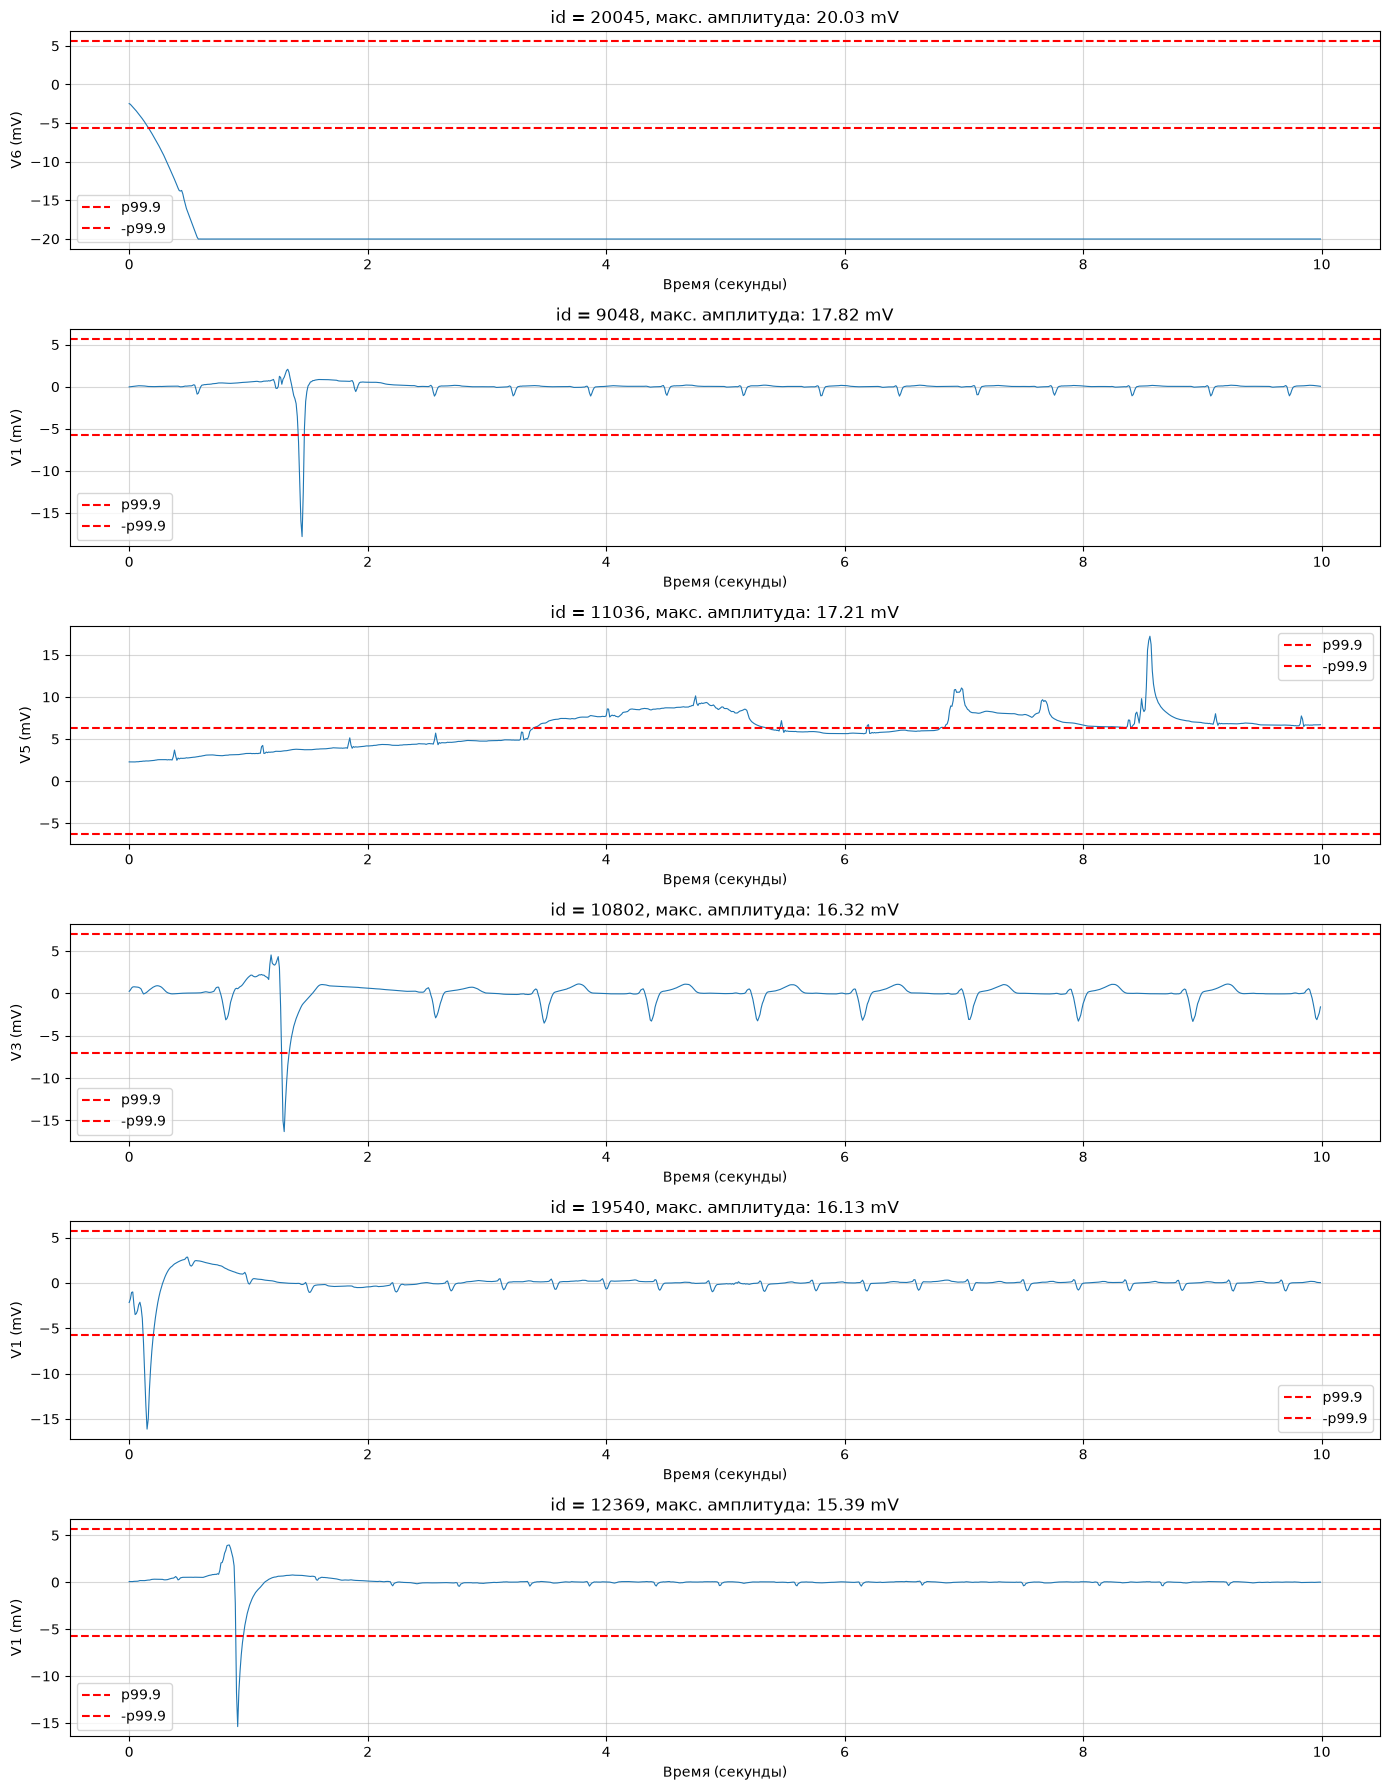

In [17]:
top_cases = extreme_amplitudes.sort_values("max_abs_mV", ascending=False).head(6)

fig, axes = plt.subplots(len(top_cases), 1, figsize=(14, 3*len(top_cases)))

for ax, (_, row) in zip(axes, top_cases.iterrows()):
    ecg_id = row["ecg_id"]
    lead = row["lead"]

    metadata_row = metadata.loc[ecg_id]
    record_path = DATA_DIR / metadata_row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))

    lead_idx = rec.sig_name.index(lead)
    values = rec.p_signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    ax.plot(time, values, linewidth=0.8)

    ax.axhline(row["p99_9_mV"], linestyle="--", color="r", label="p99.9")
    ax.axhline(-row["p99_9_mV"], linestyle="--", color="r", label="-p99.9")

    ax.set_title(f"id = {ecg_id}, макс. амплитуда: {row['max_abs_mV']:.2f} mV")
    ax.set_xlabel("Время (секунды)")
    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

**Вывод:**

В 263 отведениях из 175 записей максимальная абсолютная амплитуда превышает соответствующий 99.9-й перцентиль. Это пока не означает плохие данные. Но надо обратить на них внимание и сравнить с другими проверками.

2 возможных случая (из визуализации): 
- резкие отклонения амплитуды
- продолжительное смещение сигнала. Экстремально низкое значение записи 20045 (V6) уже было замечено при поиске постоянных участков.

## Оценка низкочастотной составляющей сигнала

In [18]:
baseline_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    baseline = uniform_filter1d(signal, size=201, axis=0) # фильтр скользящего окна

    for lead_idx, lead in enumerate(rec.sig_name):
        values = baseline[:, lead_idx]

        baseline_results.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "baseline_p95_mV": np.percentile(values, 95),
            "baseline_p05_mV": np.percentile(values, 5),
            "baseline_range_mV": np.percentile(values, 95)-np.percentile(values, 5)})

baseline_df = pd.DataFrame(baseline_results)

print("Общая статистика размаха baseline:")
display(baseline_df['baseline_range_mV'].describe())

print("Медианный размах baseline по отведениям:")
display(baseline_df.groupby("lead")['baseline_range_mV'].median().reindex(lead_order))

top_baseline = baseline_df.sort_values("baseline_range_mV", ascending=False).head(10)
print("Отведения с наибольшим размахом baseline:")
display(top_baseline.round(3))

Общая статистика размаха baseline:


count    261588.000000
mean          0.136438
std           0.230595
min           0.000000
25%           0.036999
50%           0.078008
75%           0.149045
max          10.502996
Name: baseline_range_mV, dtype: float64

Медианный размах baseline по отведениям:


lead
I      0.058843
II     0.078120
III    0.084827
AVR    0.058620
AVL    0.064463
AVF    0.075803
V1     0.071565
V2     0.090152
V3     0.095049
V4     0.092515
V5     0.090524
V6     0.089273
Name: baseline_range_mV, dtype: float64

Отведения с наибольшим размахом baseline:


,ecg_id,lead,baseline_p95_mV,baseline_p05_mV,baseline_range_mV
133175,11124,V6,6.914,-3.589,10.503
198572,16585,V3,3.149,-4.992,8.141
196979,16452,V6,3.121,-4.850,7.971
22727,1906,V6,4.564,-3.224,7.788
209975,17535,V6,4.706,-3.065,7.771
18464,1551,V3,5.222,-2.360,7.582
48417,4054,V4,2.448,-5.020,7.468
56802,4753,V1,9.945,2.618,7.327
56444,4723,V3,4.838,-2.447,7.286
16714,1405,V5,3.595,-3.641,7.236


Есть записи с большими изменениями низкочастотной составляющей

В большинстве отведений размах сглаженной составляющей небольшой. Но есть записи с очень медленными изменениями сигнала. 

Посмотрим на 5 отведений с наибольшим размахом между 5-м и 95-м перцентилями сглаженного сигнала.

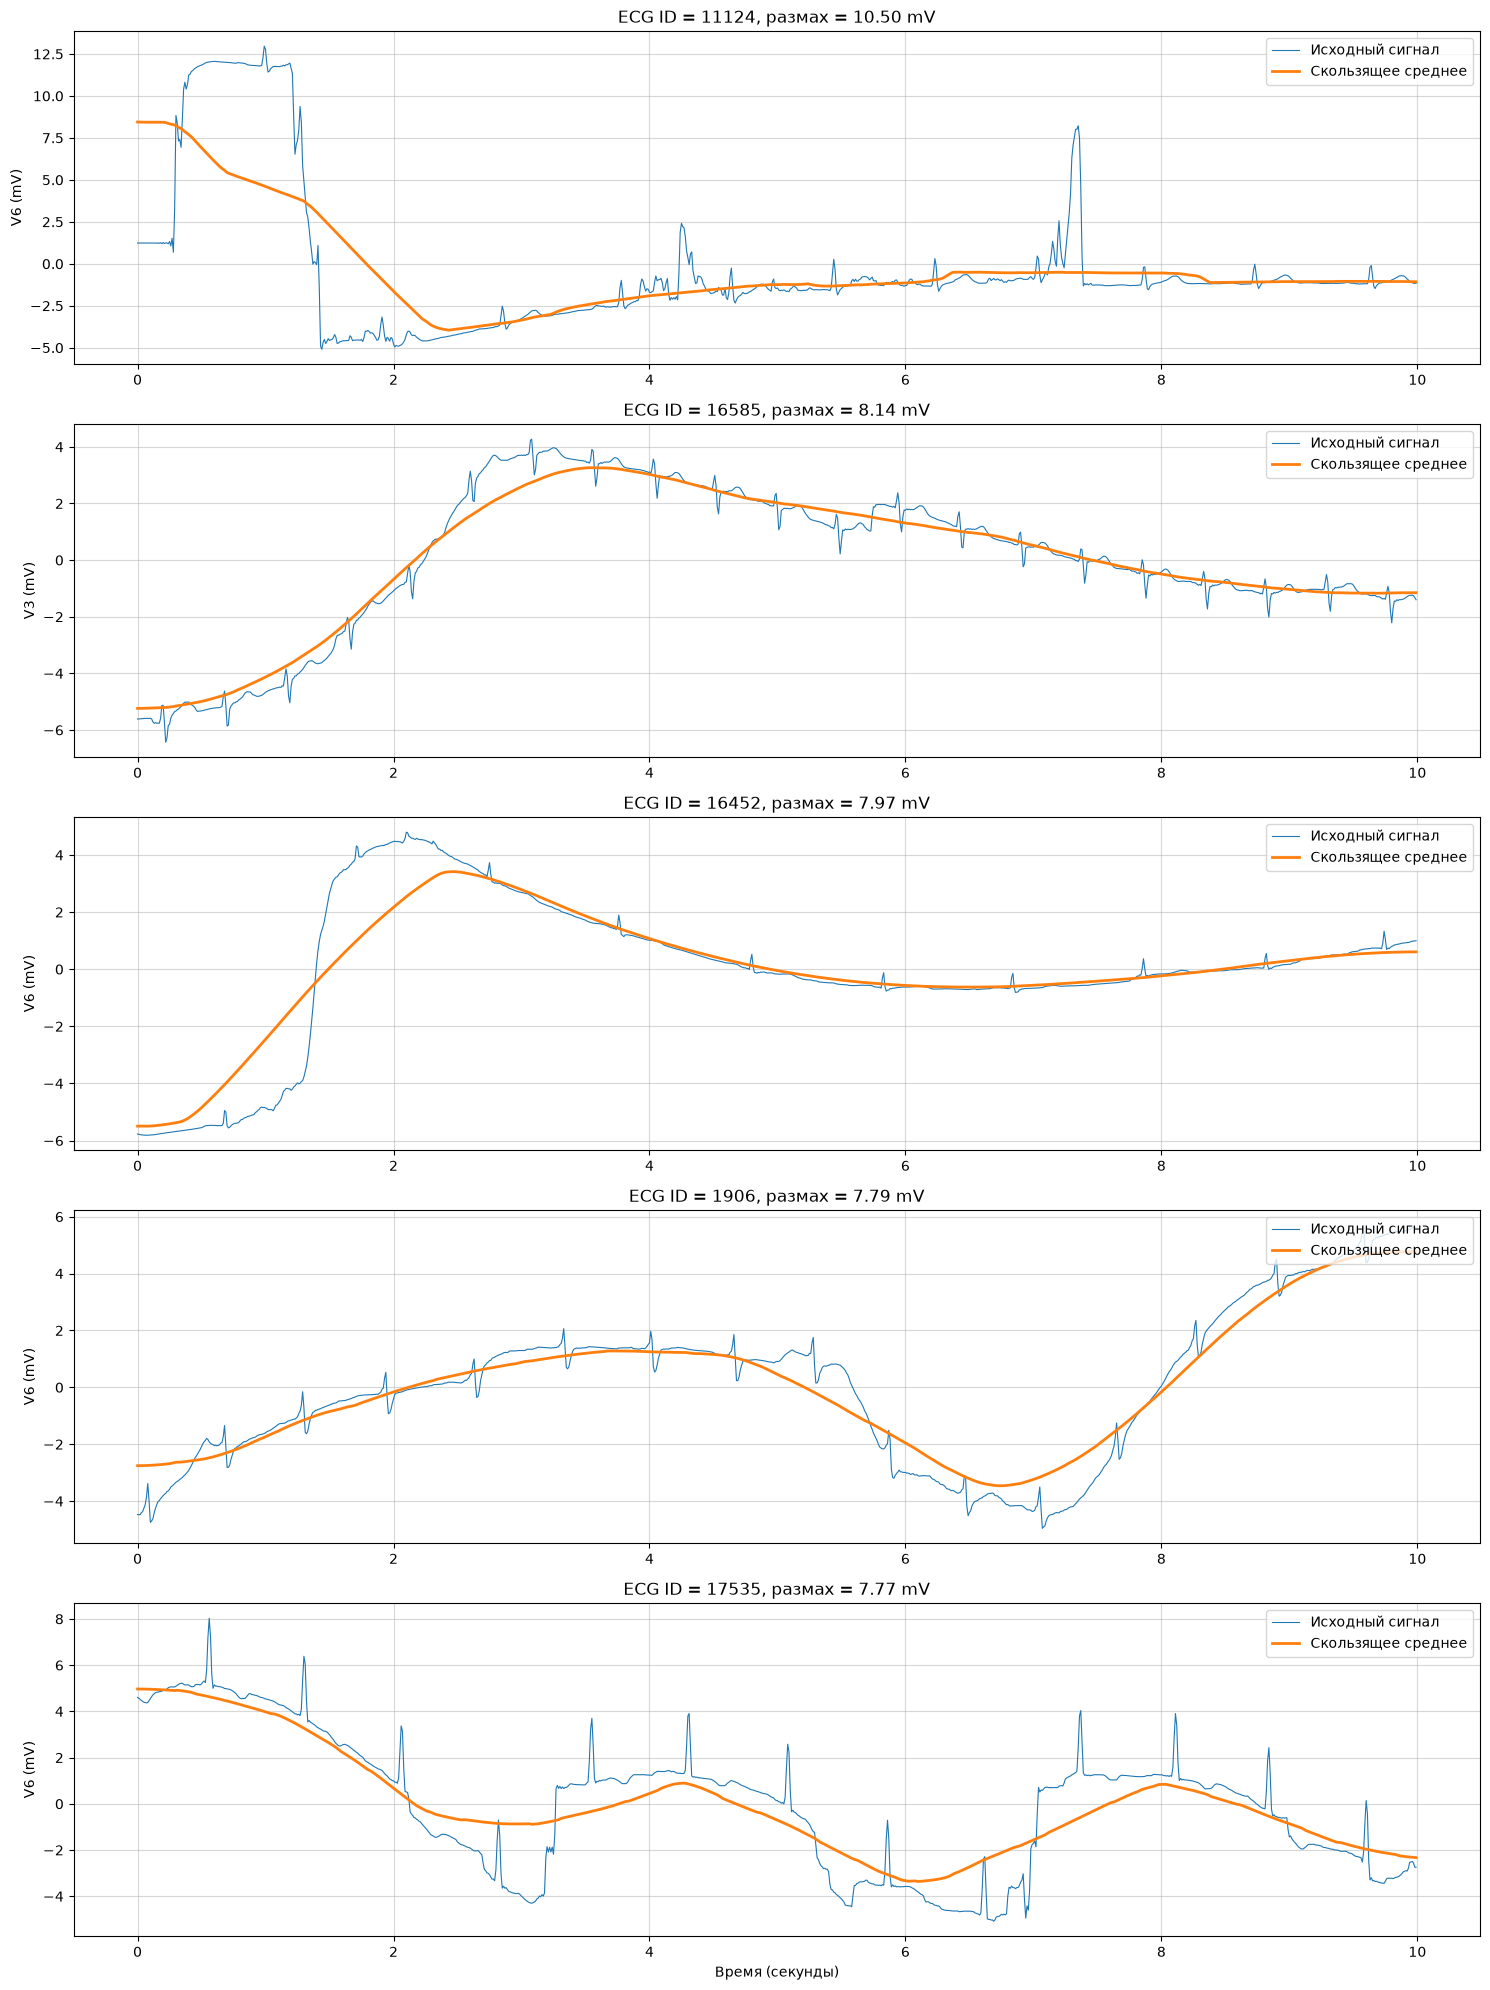

In [19]:
top_baseline = baseline_df.sort_values("baseline_range_mV", ascending=False).head(5)

fig, axes = plt.subplots(len(top_baseline), 1, figsize=(15, 4 * len(top_baseline)))

for ax, (_, item) in zip(axes, top_baseline.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    baseline = uniform_filter1d(values, size=201)

    ax.plot( time, values, linewidth=0.8, label="Исходный сигнал")
    ax.plot(time, baseline, linewidth=2, label="Скользящее среднее")
    ax.set_title(f"ECG ID = {ecg_id}, размах = {item['baseline_range_mV']:.2f} mV")
    
    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

Для приближённой оценки медленных изменений сигнала использовано скользящее среднее с окном в 201 отсчёт (~2 секунды).

Медианный размах по всем отведениям - 0.078 mV. Медианные значения отличаются между отведениями: от 0.059 mV в AVR до 0.095 mV в V3. В большинстве отведений медленные изменения относительно небольшие (как и ожидается).
Но есть отдельные записи с выраженными изменениями уровня сигнала (например максимальный размах - 10.50 mV в записи 11124, отведение V6).

*Примечание:* большой размах не гарантирует наличие шума или плохое качество записи.

На отдельных графиках видны:
- резкие переходы
- плавные смещения
- продолжительные колебания сглаженной составляющей

-> низкочастотная часть сигналов неоднородна -> при подготовке данных нужно учитывать наличие таких изменений и оценить, как их удаление повлияет на данные.

*Примечание:* скользящее среднее не может отделить технический дрейф от других медленных изменений сигнала -> говорить о плохом качестве данных нельзя

## Оценка быстрых составляющих сигнала
*Эта часть практических результатов особенно не дает, но я оставила. Суть - при удалении шума на высоких частотах важно убедиться, что это именно шум, а не характерные для ЭКГ-сигнала пики*

In [20]:
highfreq_results = []

for ecg_id, row in metadata.iterrows():
    record_path = DATA_DIR / row["filename_lr"]
    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    smooth_signal = uniform_filter1d(signal, size=5, axis=0)
    highfreq_signal = signal - smooth_signal

    # RMS для каждого отведения
    for lead_idx, lead in enumerate(rec.sig_name):
        values = highfreq_signal[:, lead_idx]

        highfreq_rms = np.sqrt(np.mean(values ** 2))

        highfreq_results.append({
            "ecg_id": int(ecg_id),
            "lead": lead,
            "highfreq_rms_mV": highfreq_rms})

highfreq_df = pd.DataFrame(highfreq_results)

print("Распределение RMS для высокочастотных колебаний:")
display(highfreq_df["highfreq_rms_mV"].describe().round(4))

print("10 отведений с наибольшим RMS:")
display(highfreq_df.sort_values("highfreq_rms_mV", ascending=False).head(10))

Распределение RMS для высокочастотных колебаний:


count    261588.0000
mean          0.0814
std           0.0499
min           0.0000
25%           0.0463
50%           0.0692
75%           0.1037
max           0.6829
Name: highfreq_rms_mV, dtype: float64

10 отведений с наибольшим RMS:


,ecg_id,lead,highfreq_rms_mV
201765,16851,V4,0.682902
202665,16926,V4,0.651676
199917,16697,V4,0.630027
79245,6624,V4,0.596788
138249,11547,V4,0.586600
23491,1970,V2,0.584770
106678,8913,V5,0.583823
23492,1970,V3,0.578121
106677,8913,V4,0.571046
211653,17675,V4,0.553695


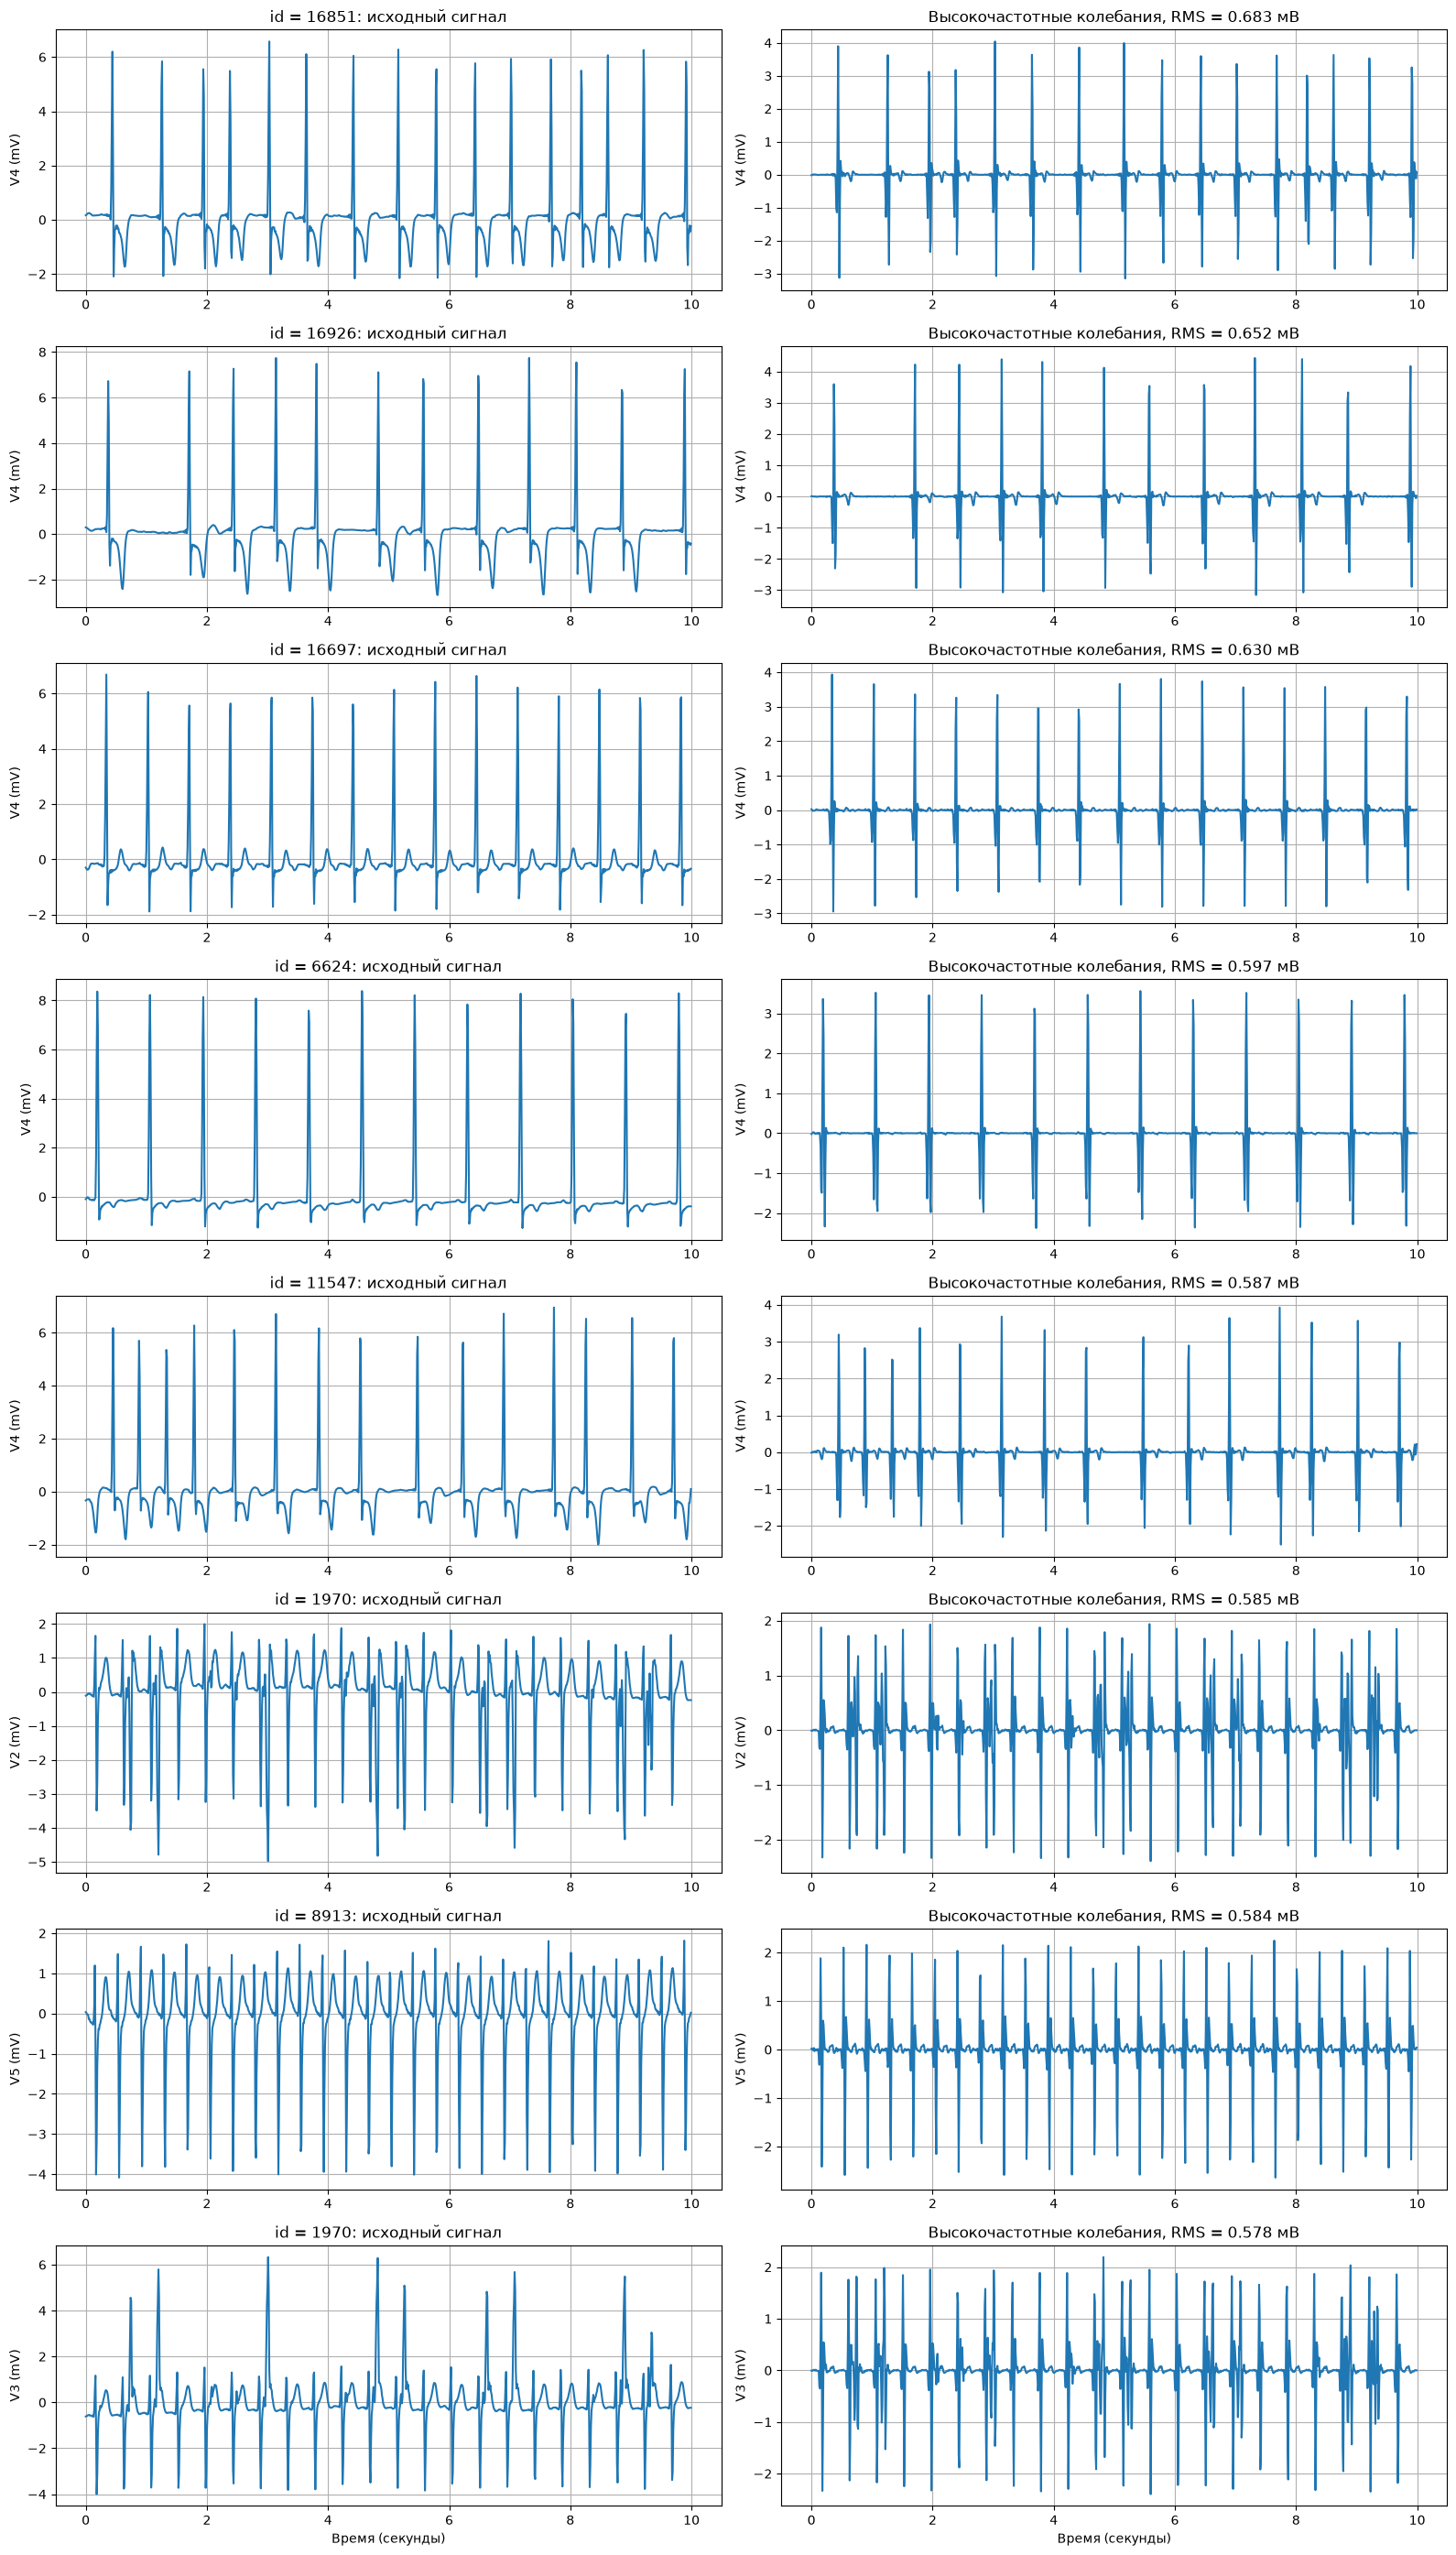

In [21]:
top_highfreq = highfreq_df.sort_values("highfreq_rms_mV", ascending=False).head(8)

fig, axes = plt.subplots(len(top_highfreq), 2, figsize=(16, 3.5 * len(top_highfreq)))

for i, (_, item) in enumerate(top_highfreq.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    lead_idx = rec.sig_name.index(lead)
    values = rec.p_signal[:, lead_idx]

    time = np.arange(len(values))/rec.fs

    smooth_signal = uniform_filter1d(values, size=5)
    highfreq_signal = values - smooth_signal

    axes[i, 0].plot(time, values)
    axes[i, 0].set_title(f"id = {ecg_id}: исходный сигнал")
    axes[i, 0].set_ylabel(f"{lead} (mV)")
    axes[i, 0].grid(True)

    axes[i, 1].plot(time, highfreq_signal)
    axes[i, 1].set_title(f"Высокочастотные колебания, RMS = {item['highfreq_rms_mV']:.3f} мВ")
    axes[i, 1].set_ylabel(f"{lead} (mV)")
    axes[i, 1].grid(True)

axes[-1, 0].set_xlabel("Время (секунды)")
axes[-1, 1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

Для оценки быстрых изменений сигнала использовано скользящее среднее с окном 5 отсчётов. Из исходного сигнала вычиталась сглаженная составляющая. RMS рассчитывалось для полученной разности отдельно для каждого отведения.

На графиках с наибольшим RMS быстрые пики повторяются и совпадают по времени с резкими скачками исходного сигнала -> данный метод также выделяет изменения самой формы ЭКГ, а не только возможный шум

## Итог по анализу ЭКГ-сигналов
Все 21799 записей имеют одинаковый формат: 10 секунд, 12 отведений, частота дискретизации 100 Гц, единицы измерения mV -> единый формат входных данных для дальнейшей работы модели.

В данных нет NaN и Inf. 

Особенности, которые важно учитывать при подготовке сигналов:

- в 4 записях найдены 7 отведений с непрерывными постоянными участками длительностью не менее 0,5 секунды. В некоторых отведениях постоянный участок занимает всю запись или большую ее часть.
- распределение амплитуд различается между отведениями. В 175 записях найдены отведения, максимальная абсолютная амплитуда которых больше соответствующего 99.9-й перцентиля.
- В большинстве отведений размах медленной составляющей относительно небольшой, но есть записи с заметными изменениями сигнала (например, 11124 (V6), 16585 (V3), 16452 (V6)).
- анализ быстрых составляющих показал не только шуум, но и пики, характерные для ЭКГ.
- визуальное сравнение примеров из разных классов показало, что сигналы могут заметно отличаться по форме и амплитуде внутри одного класса и между отведениями разных классов -> отдельная запись не может отображать тенденцию для всего класса

**Что следует учесть при подготовке входных данных для модели:**
1. **Формат входных данных.** Сохранять единый формат записей: одинаковое число отсчётов, все 12 отведений и частоту дискретизации.
2. **Контроль качества каналов.** Предусмотреть проверку постоянных участков, т.к. отдельные отведения могут содержать длительные участки без изменений. Эти данные следует дополнительно проверять, а не сразу удалять запись.
3. **Контроль амплитуд.** Учитывать различия амплитудных распределений между отведениями. При выборе способа масштабирования и нормализации проверить, не приведет ли он к потере значимых амплитудных данных.
4. **Обработка медленных изменений.** Не применять удаление низкочастотной составляющей без проверки того, как это изменит исходную форму сигнала.
5. **Сохранение данных.** При обучении лучше использовать все доступные записи и все 12 отведений, а не на несколько отобранных примеров.